# **Hedging AI: Training Agents on Synthetic Markets to Replicate Derivatives and Optimize Dynamic Portfolios Using Deep Reinforcement Learning**

Reinforcement learning (RL) is a branch of machine learning based on the continuous interaction between an agent and its environment. The agent learns to make optimal decisions by observing the consequences of its actions, receiving positive rewards or penalties. In modern applications, RL is almost always integrated with deep learning techniques, leveraging neural networks’ ability to represent complex relationships in high-dimensional input spaces.

Many problems in finance fit precisely within this framework, such as the optimal allocation of a portfolio over time. In these cases, the goal of the agent is to learn an effective policy, that is, a decision-making strategy that maximizes the reward function over a discrete time sequence.

The project has been structured into three sections, each with a well-defined experimental goal.

🔷 **Part 1 - Predictive Finance with Reinforcement Learning on Real and Synthetic Data Series**

A Finance environment has been built using real data from 12 assets. Since real series are often not sufficient to train an RL agent, they have been complemented with simulated series using the stochastic Vasicek model, calibrated to replicate the distributional properties of the original assets. The statistical validity of the simulations has been verified both with a Kolmogorov-Smirnov test and through visual and distributional comparisons.

The agent, implemented with an Advantage Actor-Critic architecture, has been trained on synthetic environments and then tested on real data. Key metrics, observed over five episodes per asset (12 synthetic series and 12 real series), are reward and accuracy.

🔷 **Part 2 - Dynamic Replication of a European Call**

After consolidating the predictive phase, the second part has explored a numerical replication of the payoff of a European call, using the Black-Scholes-Merton formula and a portfolio dynamically rebalanced between a risky asset (Microsoft) and a near risk-free asset (ETF on Physical Silver). The results are remarkable: the mean absolute error and mean squared error (MAE, MSE) have been practically zero, confirming the accuracy of the discretized replication strategy.

This section has been crucial to evaluate, in the third part, the behavior of the RL agent in non-deterministic environments.

🔷 **Part 3 - Multi-Feature Dynamic Hedging Environment**

The third section has introduced a stochastic hedging environment, in which the agent must optimize portfolio rebalancing in a highly dynamic and realistic setting, considering: index price, bond price, underlying log-return, 5-period moving average, historical volatility (rolling standard deviation), residual time to maturity, cumulative average price (expanding mean), momentum (instantaneous price change).

Unlike the theoretical replication, here the environment is realistic, noisy, and interactive. A random baseline has been analyzed to show the mismatch that occurs when a learned policy is not adopted.

This final environment, in particular, can be a starting point for the development of intelligent agents capable of processing multidimensional signals and actively adapting to highly variable and information-dense portfolio contexts.

**Libraries + Hyperparameters**

In [ ]:
import numpy as np
import pandas as pd
import math
import random
from datetime import datetime, timedelta
import os
import yfinance as yf
from scipy.stats import norm, ks_2samp
from scipy.optimize import minimize
from pylab import plt, mpl

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import models, layers, optimizers
from tensorflow.keras.models import Model
from keras.models import Sequential
from keras.layers import LSTM, Dense, Input
from tensorflow.keras.optimizers import Adam
from collections import deque

import warnings

warnings.filterwarnings("ignore")

# 1. Simulating a Trading Environment for Predictive Finance

# Real Data

We create a *Finance* environment based on real data, using the **daily closing prices** collected from `yfinance` for the period **from 2020-01-01 to 2023-01-01**. The selected assets belong to different categories:

<table>
  <tr>
    <th>Category</th>
    <th>Ticker</th>
    <th>Description</th>
  </tr>

  <tr>
    <td rowspan="4">1. Established Companies (Large Cap USA - NYSE/NASDAQ)</td>
    <td>AAPL</td>
    <td>Apple Inc.</td>
  </tr>
  <tr>
    <td>MSFT</td>
    <td>Microsoft Corporation</td>
  </tr>
  <tr>
    <td>JNJ</td>
    <td>Johnson & Johnson</td>
  </tr>
  <tr>
    <td>PG</td>
    <td>Procter & Gamble Co.</td>
  </tr>

  <tr>
    <td rowspan="3">2. Tech Stocks</td>
    <td>TSLA</td>
    <td>Tesla, Inc.</td>
  </tr>
  <tr>
    <td>NVDA</td>
    <td>NVIDIA Corporation</td>
  </tr>
  <tr>
    <td>ARKK</td>
    <td>ARK Innovation ETF (disruptive technology)</td>
  </tr>

  <tr>
    <td rowspan="3">3. Safe Haven Assets (funds/ETFs on commodities or defensive assets)</td>
    <td>IAU</td>
    <td>iShares Gold Trust</td>
  </tr>
  <tr>
    <td>USO</td>
    <td>United States Oil Fund (WTI oil ETF)</td>
  </tr>
  <tr>
    <td>SLV</td>
    <td>iShares Silver Trust (silver ETF)</td>
  </tr>

  <tr>
    <td rowspan="2">4. Global Index ETFs</td>
    <td>SPY</td>
    <td>SPDR S&P 500 ETF Trust</td>
  </tr>
  <tr>
    <td>VTI</td>
    <td>Vanguard Total Stock Market ETF</td>
  </tr>
</table>

### Preprocessing and Normalization

The collected data is preprocessed through:

- **Log return computation** for each asset  
- **Weekly aggregation** to reduce daily noise  
- **Z-score normalization** to improve numerical stability and robustness of the series

In [ ]:

class ActionSpace:
    def __init__(self):
        self.n = 2  # 0 = short/no change, 1 = long

    def sample(self):
        return random.randint(0, 1)

class Finance:
    def __init__(self, symbol, feature='Close', n_features=10, min_accuracy=0.485,
                 start=None, end=None, normalize=True):
        self.symbol = symbol.upper()
        self.feature = feature
        self.n_features = n_features
        self.min_accuracy = min_accuracy
        self.normalize = normalize
        self.action_space = ActionSpace()

        self.start = start or (datetime.now() - timedelta(days=730)).strftime('%Y-%m-%d')
        self.end = end or datetime.now().strftime('%Y-%m-%d')

        self._load_data()
        self._prepare_data()

    def _load_data(self):
        print(f"[+] Downloading data for {self.symbol} from Yahoo Finance...")
        df = yf.download(self.symbol, start=self.start, end=self.end, interval='1d')
        if df.empty:
            raise ValueError(f"No data available for {self.symbol}.")
        df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
        df = df.round(2)
        self.raw = df

    def _prepare_data(self):
        # Weekly average of all columns
        weekly_data = self.raw.resample('W').mean()

        # Weekly log-returns calculated using the mean over all columns (to create a single series)
        weekly_mean = weekly_data.mean(axis=1)
        self.data = pd.DataFrame(weekly_mean, columns=['weekly_mean'])

        # Weekly log returns and direction indicator
        self.data['r'] = np.log(self.data['weekly_mean'] / self.data['weekly_mean'].shift(1))
        self.data['d'] = (self.data['r'] > 0).astype(int)
        self.data.dropna(inplace=True)

        # (z-score) normalization of the weekly_mean series for network input
        if self.normalize:
            mu = self.data['weekly_mean'].mean()
            sigma = self.data['weekly_mean'].std()
            self.data_ = (self.data['weekly_mean'] - mu) / sigma
        else:
            self.data_ = self.data['weekly_mean'].copy()

    def reset(self):
        self.bar = self.n_features
        self.treward = 0
        self.accuracy = 0
        state = self.data_.iloc[self.bar - self.n_features:self.bar].values
        return state, {}

    def step(self, action):
        correct = action == self.data['d'].iloc[self.bar]
        reward = 1 if correct else 0
        self.treward += reward
        self.bar += 1
        self.accuracy = self.treward / (self.bar - self.n_features)

        done = False
        if self.bar >= len(self.data):
            done = True
        elif reward == 0 and self.accuracy < self.min_accuracy and self.bar > 15:
            done = True

        next_state = self.data_.iloc[self.bar - self.n_features:self.bar].values
        return next_state, reward, done, False, {}


# Synthetic Data - Data Augmentation and Monte Carlo Simulations

An important limitation of the financial environment is the scarcity of data because the execution relies on a single historical financial series, which is too limited an environment to train a Reinforcement Learning agent. The risk is producing a model unable to generalize predictions across all historical series (overfitting).

One approach is to generate financial time series through simulation under certain assumptions and constraints, in order to add complexity and variety in training the agent and achieve solid and realistic results during prediction. Varying the noise level can make the generated series very similar to the characteristics of the markets on which the agent is training. The Simulation class allows generating series by controlling the following parameters:

- theta: long-term mean value (drift)
- kappa: speed of reversion to theta (mean-reversion)
- sigma: volatility of the process

Synthetic time series are generated through Monte Carlo simulation, assuming stochastic hypotheses with specific trends. Each simulated trajectory represents a possible scenario of evolution.

The model underlying the choice of hyperparameters is the Vasicek model (1977), here used to create synthetic stock series with realistic behavior.

In [ ]:
class Simulation:
    def __init__(self, symbol, feature, n_features,
                 start=None, end=None, periods=None,
                 min_accuracy=0.525, x0=100,
                 kappa=1.0, theta=100, sigma=0.2,
                 normalize=True, new=False, data_real=None):

        # Map real symbols to SIM#
        symbol_map = {
            'AAPL': 'SIM1',
            'MSFT': 'SIM2',
            'JNJ': 'SIM3',
            'PG': 'SIM4',
            'TSLA': 'SIM5',
            'NVDA': 'SIM6',
            'ARKK': 'SIM7',
            'IAU': 'SIM8',
            'USO': 'SIM9',
            'SLV': 'SIM10',
            'SPY': 'SIM11',
            'VTI': 'SIM12'
        }
        self.symbol = symbol_map.get(symbol.upper(), symbol)

        self.feature = feature
        self.n_features = n_features
        self.min_accuracy = min_accuracy
        self.normalize = normalize
        self.new = new
        self.x0 = x0
        self.kappa = kappa
        self.theta = theta
        self.sigma = sigma
        self.action_space = ActionSpace()

        if data_real is not None:
            self.data = data_real.copy()
            self._prepare_data(real_data=True)
        else:
            self.start = pd.to_datetime(start)
            self.end = pd.to_datetime(end)
            self.periods = periods
            self._simulate_data()
            self._prepare_data()

    def _simulate_data(self):
        # Simulate daily data over a date range
        index = pd.date_range(start=self.start, end=self.end, freq='D')
        n = len(index)
        dt = 1 / 252  # annualized time step (daily)

        x = [self.x0]
        for t in range(1, n):
            shock = np.random.normal(0, 1)
            xt = (x[-1]
                  + self.kappa * (self.theta - x[-1]) * dt
                  + x[-1] * self.sigma * np.sqrt(dt) * shock)
            x.append(xt)

        df = pd.DataFrame(x, columns=[self.symbol], index=index)

        # Weekly average as in Finance (weekly resample)
        weekly = df.resample('W').mean()

        self.data = weekly

    def _prepare_data(self, real_data=False):
        # Calculate weekly average using the mean of all columns on a weekly basis
        weekly_data = self.data.resample('W').mean() if real_data else self.data

        # Calculate weekly log-returns of the weekly mean (using mean of all columns)
        weekly_mean = weekly_data.mean(axis=1)
        self.data = pd.DataFrame(weekly_mean, columns=['weekly_mean'])
        self.data['r'] = np.log(self.data['weekly_mean'] / self.data['weekly_mean'].shift(1))
        self.data['d'] = (self.data['r'] > 0).astype(int)
        self.data.dropna(inplace=True)

        # Normalization of the weekly_mean series
        if self.normalize:
            mu = self.data['weekly_mean'].mean()
            sigma = self.data['weekly_mean'].std()
            self.data_ = (self.data['weekly_mean'] - mu) / sigma
        else:
            self.data_ = self.data['weekly_mean'].copy()

    def _get_state(self):
        return self.data_.iloc[self.bar - self.n_features:self.bar].values

    def seed(self, seed):
        np.random.seed(seed)
        random.seed(seed)
        tf.random.set_seed(seed)

    def reset(self):
        self.treward = 0
        self.accuracy = 0
        self.bar = self.n_features

        if self.new:
            self._simulate_data()
            self._prepare_data()

        return self._get_state(), {}

    def step(self, action):
        correct = action == self.data['d'].iloc[self.bar]
        reward = 1 if correct else 0
        self.treward += reward
        self.bar += 1
        self.accuracy = self.treward / (self.bar - self.n_features)

        done = False
        if self.bar >= len(self.data):
            done = True
        elif reward == 0 and self.accuracy < self.min_accuracy and self.bar > 25:
            done = True

        next_state = self.data_.iloc[self.bar - self.n_features:self.bar].values
        return next_state, reward, done, False, {}

# Verification of Real / Synthetic Data Relationship with Kolmogorov-Smirnov Test

We verify the relationship with:

- Kolmogorov-Smirnov (KS) test, to evaluate the similarity between two univariate distributions.
- Performance chart of the historical series for each pair.
- Comparison chart of the Cumulative Distribution Function (CDF).

In [ ]:
tickers = [
    "AAPL", "MSFT", "JNJ", "PG",
    "TSLA", "NVDA", "ARKK",
    "IAU", "USO", "SLV",
    "SPY", "VTI"
]

real_data_dict = {}

for symbol in tickers:
    data = yf.download(symbol, start="2020-01-01", end="2023-01-01", interval="1d")
    if not data.empty:
        real_data_dict[symbol] = data
    else:
        print(f"No data for {symbol}")

# Now calculate weekly log returns and save them in rets_raw
rets_raw = {}
for symbol in tickers:
    prices = real_data_dict[symbol]['Close']
    weekly_prices = prices.resample('W').mean()  # weekly average
    log_returns = np.log(weekly_prices / weekly_prices.shift(1)).dropna()
    rets_raw[symbol] = log_returns.values


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Configurations for each simulated symbol

sim_configs = [
    {"kappa": 1.0, "theta": 100, "sigma": 0.2},  # SIM1 vs AAPL
    {"kappa": 0.9, "theta": 110, "sigma": 0.25}, # SIM2 vs MSFT
    {"kappa": 0.8, "theta": 90,  "sigma": 0.15}, # SIM3 vs JNJ
    {"kappa": 1.2, "theta": 95,  "sigma": 0.18}, # SIM4 vs PG
    {"kappa": 1.1, "theta": 150, "sigma": 0.35}, # SIM5 vs TSLA
    {"kappa": 1.3, "theta": 140, "sigma": 0.30}, # SIM6 vs NVDA
    {"kappa": 0.7, "theta": 80,  "sigma": 0.22}, # SIM7 vs ARKK
    {"kappa": 0.6, "theta": 70,  "sigma": 0.12}, # SIM8 vs IAU
    {"kappa": 1.5, "theta": 60,  "sigma": 0.40}, # SIM9 vs USO
    {"kappa": 1.0, "theta": 50,  "sigma": 0.28}, # SIM10 vs SLV
    {"kappa": 0.85,"theta": 120, "sigma": 0.2},  # SIM11 vs SPY
    {"kappa": 0.95,"theta": 115, "sigma": 0.18}, # SIM12 vs VTI
]

synthetic_dict = {}
for i, symbol in enumerate(tickers):
    sim_cfg = sim_configs[i]
    sim = Simulation(
        symbol=symbol,
        feature='Close',
        n_features=10,
        start='2022-06-26',
        end='2024-06-26',
        kappa=sim_cfg["kappa"],
        theta=sim_cfg["theta"],
        sigma=sim_cfg["sigma"],
        normalize=False
    )
    synthetic_dict[f"SIM{i+1}"] = sim.data['r'].to_numpy()

Kolmogorov-Smirnov (KS) Test

In [ ]:
print("=== KS Test Results ===")
for i, symbol in enumerate(tickers):
    synth = synthetic_dict[f"SIM{i+1}"].flatten()
    real = rets_raw[symbol].flatten()
    pval = ks_2samp(synth, real).pvalue
    print(f"{i+1:02d}. SIM{i+1} vs {symbol}: KS p-value = {float(pval):.4f}")


=== KS Test Results ===
01. SIM1 vs AAPL: KS p-value = 0.0574
02. SIM2 vs MSFT: KS p-value = 0.1544
03. SIM3 vs JNJ: KS p-value = 0.9130
04. SIM4 vs PG: KS p-value = 0.1872
05. SIM5 vs TSLA: KS p-value = 0.0513
06. SIM6 vs NVDA: KS p-value = 0.1969
07. SIM7 vs ARKK: KS p-value = 0.0026
08. SIM8 vs IAU: KS p-value = 0.1434
09. SIM9 vs USO: KS p-value = 0.2365
10. SIM10 vs SLV: KS p-value = 0.0212
11. SIM11 vs SPY: KS p-value = 0.1691
12. SIM12 vs VTI: KS p-value = 0.2031


**KS Test Results**

The Kolmogorov-Smirnov test (KS test) checks whether two data distributions (in this case synthetic and real returns) come from the same distribution. The reported value is the p-value:

* **High p-value (typically > 0.05)** means we cannot reject the null hypothesis: the distributions could be similar.
* **Low p-value (typically < 0.05)** indicates that the distributions differ significantly.

**Results analysis:**

* Most symbols show a reasonable match between synthetic and real returns.
* For ARKK and SLV, the KS test highlights a difference, so the simulated model might not capture all details of the real distribution during training.

**Visual Comparison via Histograms**

This histogram shows the distribution similarity between real and synthetic returns.

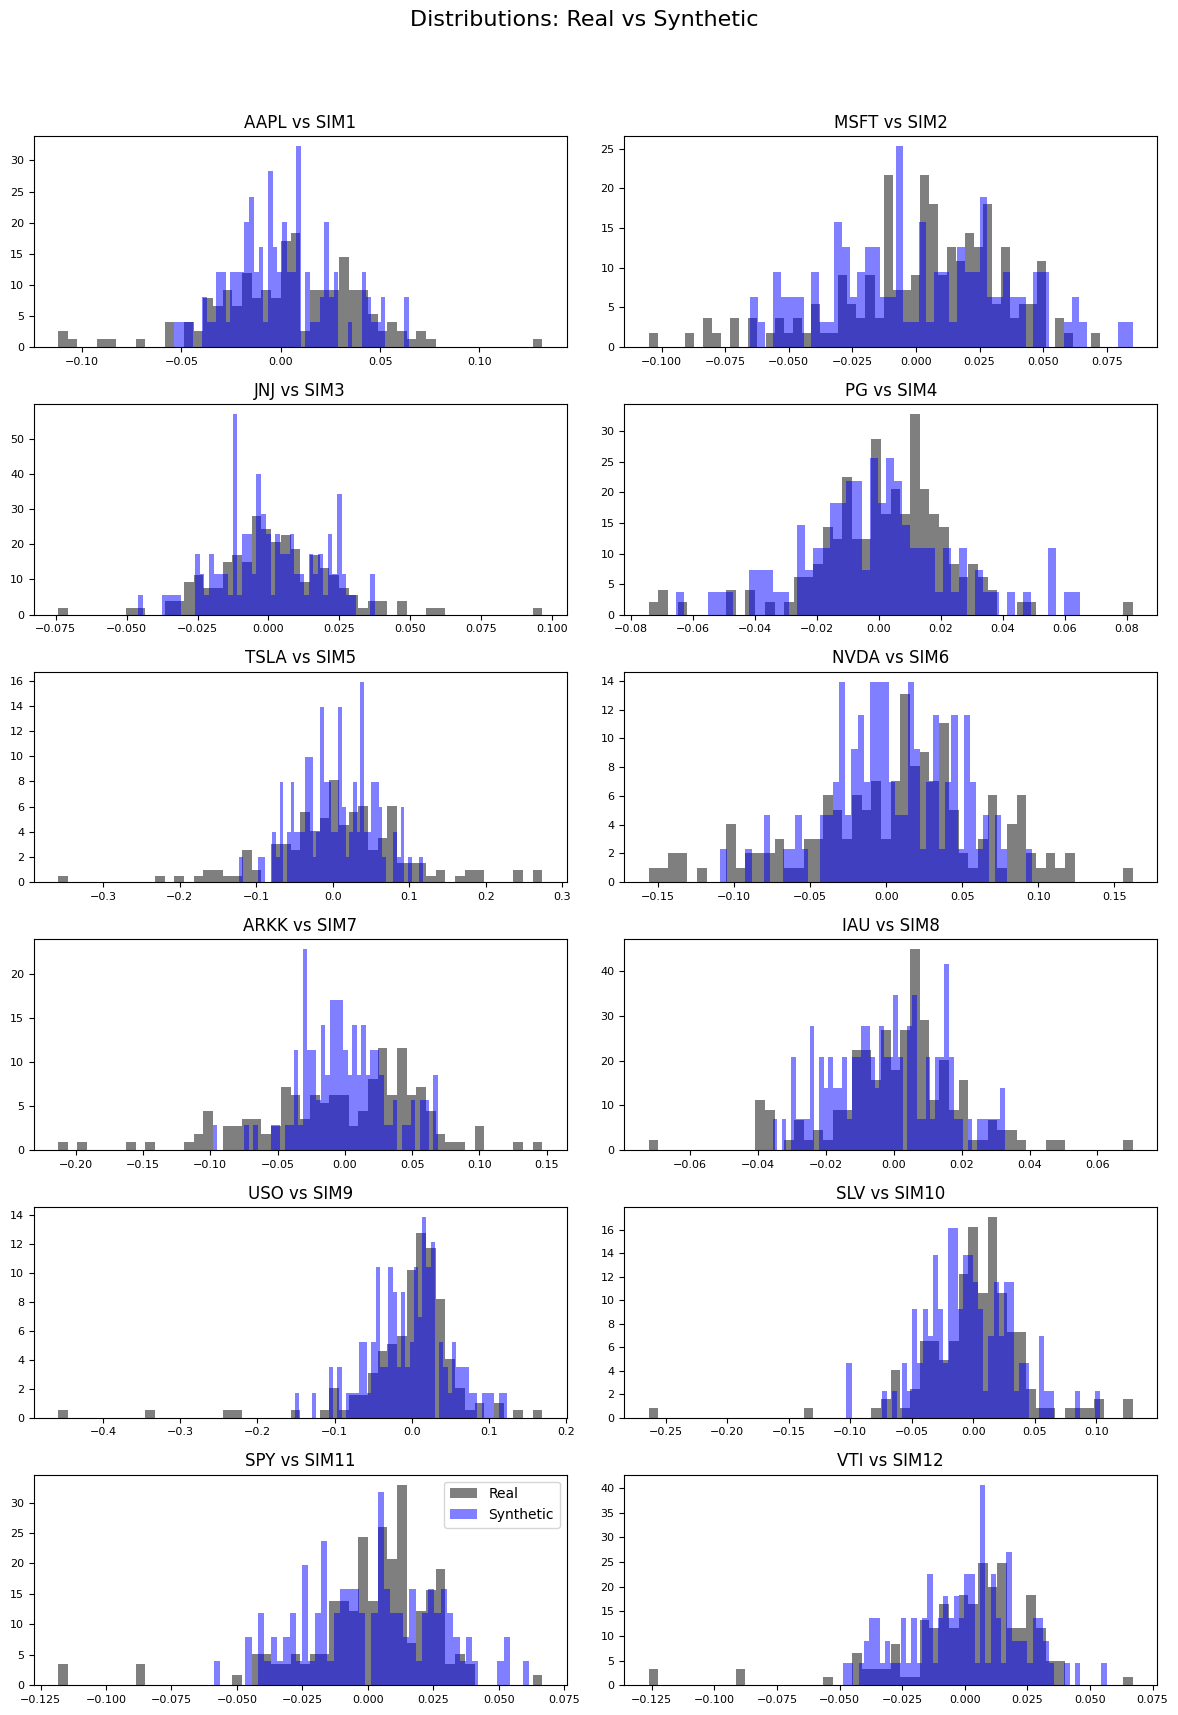

In [ ]:
fig, axs = plt.subplots(6, 2, figsize=(12, 18))
fig.suptitle("Distributions: Real vs Synthetic", fontsize=16)

for i, symbol in enumerate(tickers):
    row, col = divmod(i, 2)
    ax = axs[row, col]

    real = rets_raw[symbol].flatten()
    synth = synthetic_dict[f"SIM{i+1}"].flatten()

    ax.hist(real, bins=50, alpha=0.5, label="Real", color="black", density=True)
    ax.hist(synth, bins=50, alpha=0.5, label="Synthetic", color="blue", density=True)

    ax.set_title(f"{symbol} vs SIM{i+1}")
    ax.tick_params(labelsize=8)

    if row == 5 and col == 0:
        ax.legend(loc="upper right", fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


**Comparison via Cumulative Distribution Function (CDF)**

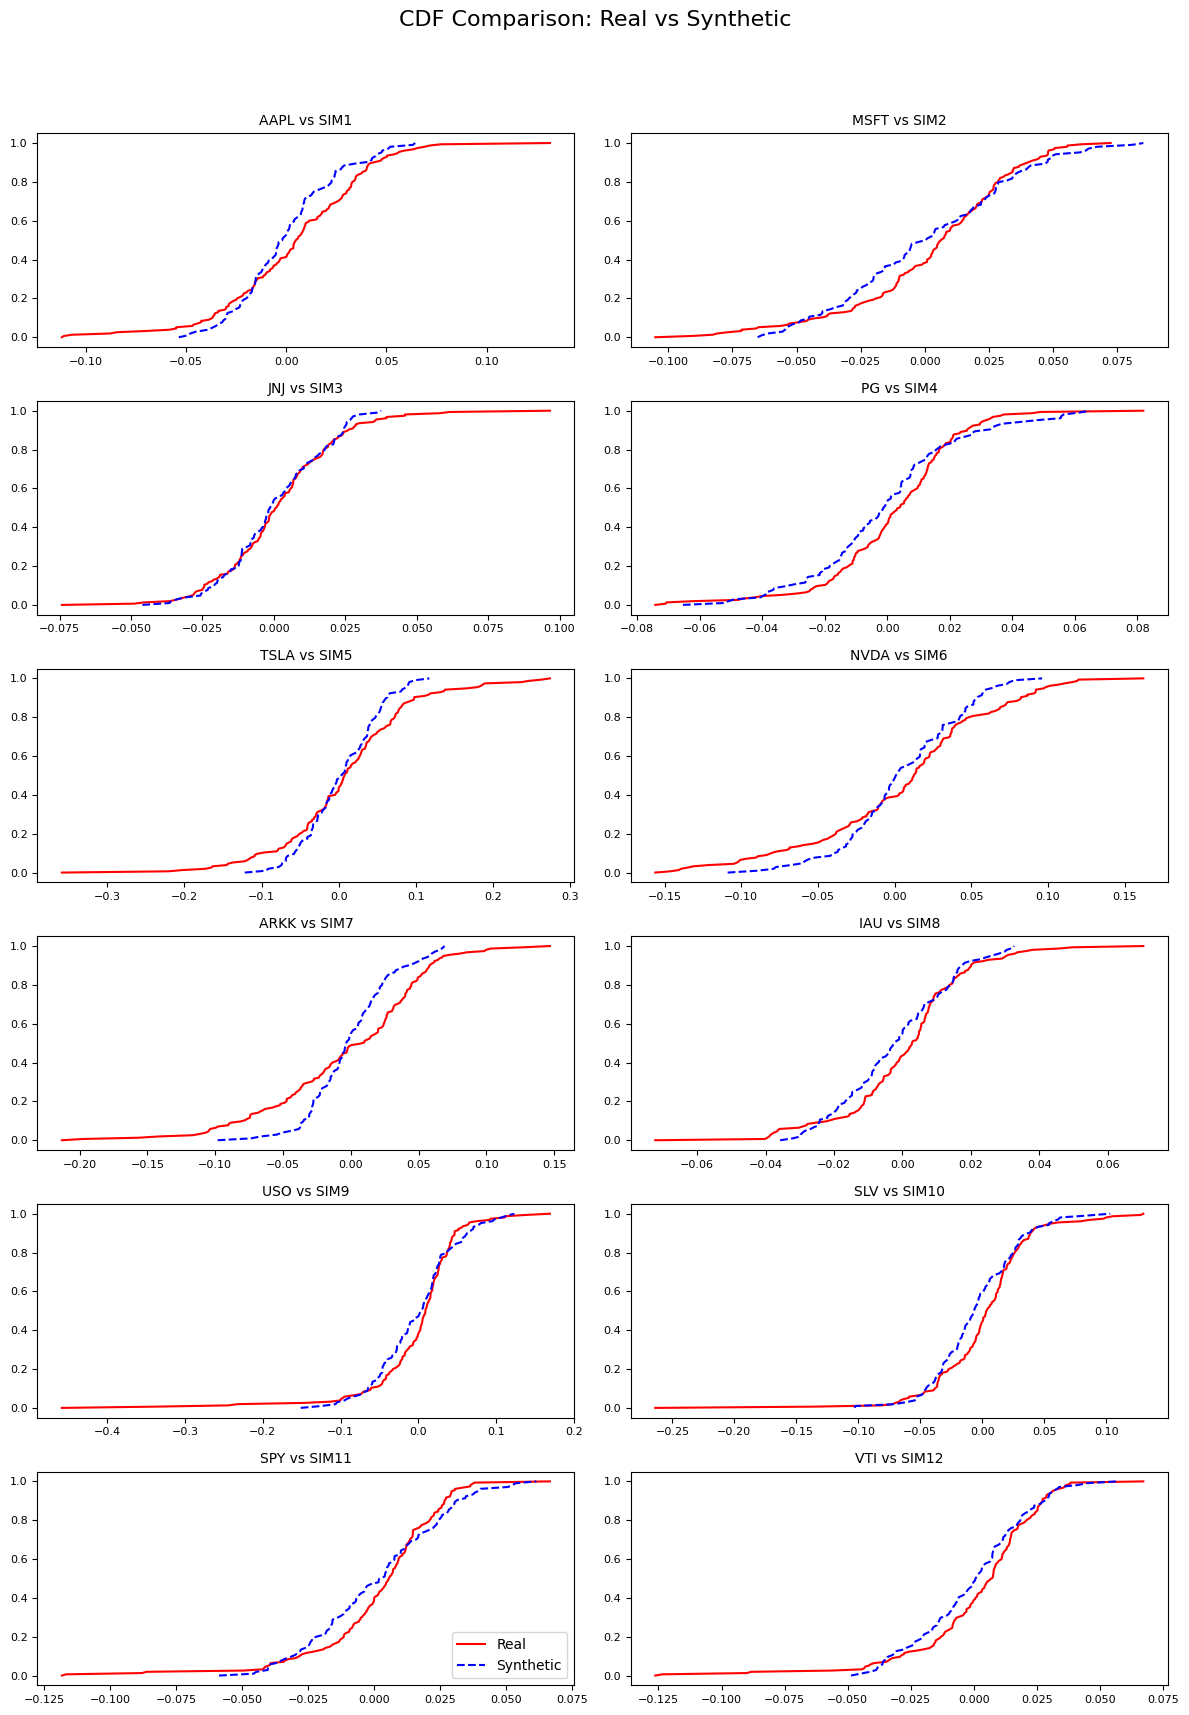

In [ ]:
fig, axs = plt.subplots(6, 2, figsize=(12, 18))
fig.suptitle("CDF Comparison: Real vs Synthetic", fontsize=16)

for i, symbol in enumerate(tickers):
    row, col = divmod(i, 2)
    ax = axs[row, col]

    real = np.sort(rets_raw[symbol].flatten())
    synth = np.sort(synthetic_dict[f"SIM{i+1}"].flatten())

    real_cdf = np.linspace(0, 1, len(real))
    synth_cdf = np.linspace(0, 1, len(synth))

    ax.plot(real, real_cdf, 'r', lw=1.5, label='Real')
    ax.plot(synth, synth_cdf, 'b--', lw=1.5, label='Synthetic')

    ax.set_title(f"{symbol} vs SIM{i+1}", fontsize=10)
    ax.tick_params(labelsize=8)

    if row == 5 and col == 0:  # legend bottom right
        ax.legend(loc='lower right', fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


The synthetic return’s CDF also replicates the real one well.

# Neural Network Model with RL Agent and Three Actions ('sell', 'buy', 'hold')

We adopted an Advantage Actor-Critic (A2C) model, a Reinforcement Learning algorithm that combines an actor, responsible for choosing the action, and a critic, which evaluates the quality of actions by estimating the state value. Thanks to the simultaneous updating of both models based on value function gradients, A2C ensures more stable and efficient learning, accelerating convergence compared to traditional methods.

Our model integrates:

* Entropy in the loss to improve exploration.
* Reward normalization, positively calibrating effective actions and penalizing useless or harmful ones.
* Gradients calculated with Advantage, through a simplified version of Generalized Advantage Estimation (GAE).

Training was conducted on synthetic data, while testing was performed on 12 real equity assets.

Definition of A2C Neural Networks

In [ ]:
def build_actor(input_shape, num_actions):
    inputs = Input(shape=(input_shape,))
    x = Dense(64, activation='relu')(inputs)
    x = Dense(64, activation='relu')(x)
    outputs = Dense(num_actions, activation='softmax')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.0003))
    return model

def build_critic(input_shape):
    inputs = Input(shape=(input_shape,))
    x = Dense(64, activation='relu')(inputs)
    x = Dense(64, activation='relu')(x)
    outputs = Dense(1, activation='linear')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.0003), loss='mse')
    return model


Replay Buffer

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        samples = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*samples)
        return (
            np.array(states),
            np.array(actions),
            np.array(rewards),
            np.array(next_states),
            np.array(dones)
        )

    def __len__(self):
        return len(self.buffer)


Action Selection Function


In [ ]:
def select_action(state, actor_model):
    state = np.expand_dims(state, axis=0)
    probs = actor_model.predict(state, verbose=0)[0]
    action = np.random.choice(len(probs), p=probs)
    return action

Constants and Hyperparameters

In [ ]:
GAMMA = 0.99
LEARNING_RATE = 0.0003
BATCH_SIZE = 64
MEMORY_SIZE = 100000
EPISODES = 5

sim_configs = [
    {"symbol": f"SIM{i+1}", "kappa": k, "theta": t, "sigma": s}
    for i, (k, t, s) in enumerate([
        (1.0, 100, 0.2), (0.9, 110, 0.25), (0.8, 90, 0.15),
        (1.2, 95, 0.18), (1.1, 150, 0.35), (1.3, 140, 0.30),
        (0.7, 80, 0.22), (0.6, 70, 0.12), (1.5, 60, 0.40),
        (1.0, 50, 0.28), (0.85, 120, 0.2), (0.95, 115, 0.18)
    ])
]

tickers = ["AAPL", "MSFT", "JNJ", "PG", "TSLA", "NVDA", "ARKK", "IAU", "USO", "SLV", "SPY", "VTI"]

n_features = 10
action_size = 3  # # sell, buy, hold

actor = build_actor(n_features, action_size)
critic = build_critic(n_features)
memory = ReplayBuffer(MEMORY_SIZE)
episode_rewards = []
test_rewards = []


Training Function

In [ ]:
def train_agent(env, tag):
    for ep in range(EPISODES):
        state, _ = env.reset()
        total_reward = 0
        correct_predictions = 0
        step_count = 0
        done = False

        while not done:
            action = select_action(state, actor)
            next_state, reward, done, _, _ = env.step(action)

            if reward == 1:
                correct_predictions += 1
            step_count += 1

            if done and reward <= 0:
                reward = -0.5

            memory.push(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward

            if len(memory) >= BATCH_SIZE:
                s, a, r, s2, d = memory.sample(BATCH_SIZE)
                r = (r - np.mean(r)) / (np.std(r) + 1e-10)

                values = critic.predict(s, verbose=0).flatten()
                next_values = critic.predict(s2, verbose=0).flatten()
                targets = r + (1 - d) * GAMMA * next_values
                advantages = targets - values

                critic.fit(s, targets, epochs=1, verbose=0)

                actions_one_hot = tf.keras.utils.to_categorical(a, num_classes=action_size)
                with tf.GradientTape() as tape:
                    probs = actor(s, training=True)
                    selected_action_probs = tf.reduce_sum(probs * actions_one_hot, axis=1)
                    log_probs = tf.math.log(selected_action_probs + 1e-10)
                    entropy = -tf.reduce_sum(probs * tf.math.log(probs + 1e-10), axis=1)
                    loss = -tf.reduce_mean(log_probs * advantages + 0.01 * entropy)

                grads = tape.gradient(loss, actor.trainable_variables)
                actor.optimizer.apply_gradients(zip(grads, actor.trainable_variables))

        accuracy = correct_predictions / step_count if step_count > 0 else 0
        episode_rewards.append(total_reward)
        print(f"[{tag}] Ep{ep+1}: reward={total_reward:.0f}, acc={accuracy:.2f}")


Training on synthetic series

In [ ]:
for cfg in sim_configs:
    env = Simulation(
        symbol=cfg["symbol"],
        feature=cfg["symbol"],
        n_features=n_features,
        start="2020-01-01",
        end="2023-01-01",
        periods=100,
        kappa=cfg["kappa"],
        theta=cfg["theta"],
        sigma=cfg["sigma"],
        normalize=True,
        new=True
    )
    train_agent(env, tag=f"SIM-{cfg['symbol']}")

[SIM-SIM1] Ep1: reward=2, acc=0.12
[SIM-SIM1] Ep2: reward=2, acc=0.12
[SIM-SIM1] Ep3: reward=6, acc=0.35
[SIM-SIM1] Ep4: reward=6, acc=0.35
[SIM-SIM1] Ep5: reward=4, acc=0.25
[SIM-SIM2] Ep1: reward=4, acc=0.31
[SIM-SIM2] Ep2: reward=8, acc=0.44
[SIM-SIM2] Ep3: reward=6, acc=0.37
[SIM-SIM2] Ep4: reward=6, acc=0.37
[SIM-SIM2] Ep5: reward=10, acc=0.52
[SIM-SIM3] Ep1: reward=4, acc=0.25
[SIM-SIM3] Ep2: reward=6, acc=0.38
[SIM-SIM3] Ep3: reward=6, acc=0.44
[SIM-SIM3] Ep4: reward=8, acc=0.50
[SIM-SIM3] Ep5: reward=14, acc=0.52
[SIM-SIM4] Ep1: reward=6, acc=0.38
[SIM-SIM4] Ep2: reward=84, acc=0.58
[SIM-SIM4] Ep3: reward=8, acc=0.50
[SIM-SIM4] Ep4: reward=88, acc=0.61
[SIM-SIM4] Ep5: reward=22, acc=0.52
[SIM-SIM5] Ep1: reward=84, acc=0.58
[SIM-SIM5] Ep2: reward=86, acc=0.60
[SIM-SIM5] Ep3: reward=32, acc=0.52
[SIM-SIM5] Ep4: reward=8, acc=0.50
[SIM-SIM5] Ep5: reward=8, acc=0.50
[SIM-SIM6] Ep1: reward=82, acc=0.56
[SIM-SIM6] Ep2: reward=64, acc=0.52
[SIM-SIM6] Ep3: reward=84, acc=0.58
[SIM-SIM6

Testing on real data

In [ ]:
action_log_real = []
action_log_pred = []
test_rewards = []

def test_agent(env, tag, actor_model):
    state, _ = env.reset()
    done = False
    total_reward = 0
    correct_predictions = 0
    step_count = 0

    while not done:
        action = select_action(state, actor_model)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        true_action = info.get("true_action", None) if isinstance(info, dict) else None

        if true_action is not None:
            action_log_real.append(true_action)
            action_log_pred.append(action)

        total_reward += reward
        if reward == 1:
            correct_predictions += 1
        step_count += 1
        state = next_state

    accuracy = correct_predictions / step_count if step_count > 0 else 0
    print(f"[TEST {tag}] Reward={total_reward:.0f}, Accuracy={accuracy:.2f}")
    return total_reward, accuracy

# Test loop for each asset
for symbol in tickers:
    print(f"\n=== {symbol} ===")
    env = Finance(symbol, n_features=n_features, normalize=True)
    rewards, accuracies = [], []

    for i in range(5):
        print(f"Episode {i+1}")
        reward, acc = test_agent(env, tag=f"{symbol} Ep.{i+1}", actor_model=actor)
        rewards.append(reward)
        accuracies.append(acc)
        test_rewards.append(reward)

    avg_reward = sum(rewards) / len(rewards)
    avg_accuracy = sum(accuracies) / len(accuracies)
    print(f"[{symbol}]: Average Reward = {avg_reward:.2f}, Average Accuracy = {avg_accuracy:.2f}\n")


[*********************100%***********************]  1 of 1 completed


=== AAPL ===
[+] Downloading data for AAPL from Yahoo Finance...
Episode 1


[TEST AAPL Ep.1] Reward=58, Accuracy=0.62
Episode 2
[TEST AAPL Ep.2] Reward=9, Accuracy=0.47
Episode 3
[TEST AAPL Ep.3] Reward=9, Accuracy=0.47
Episode 4
[TEST AAPL Ep.4] Reward=11, Accuracy=0.48
Episode 5


[*********************100%***********************]  1 of 1 completed

[TEST AAPL Ep.5] Reward=11, Accuracy=0.48
[AAPL]: Average Reward = 19.60, Average Accuracy = 0.50


=== MSFT ===
[+] Downloading data for MSFT from Yahoo Finance...
Episode 1


[TEST MSFT Ep.1] Reward=4, Accuracy=0.44
Episode 2
[TEST MSFT Ep.2] Reward=3, Accuracy=0.43
Episode 3
[TEST MSFT Ep.3] Reward=3, Accuracy=0.43
Episode 4
[TEST MSFT Ep.4] Reward=3, Accuracy=0.43
Episode 5


... (26 outputs left out)

[TEST SPY Ep.1] Reward=6, Accuracy=0.46
Episode 2
[TEST SPY Ep.2] Reward=6, Accuracy=0.46
Episode 3
[TEST SPY Ep.3] Reward=6, Accuracy=0.46
Episode 4
[TEST SPY Ep.4] Reward=6, Accuracy=0.46
Episode 5


[*********************100%***********************]  1 of 1 completed

[TEST SPY Ep.5] Reward=6, Accuracy=0.46
[SPY]: Average Reward = 6.00, Average Accuracy = 0.46


=== VTI ===
[+] Downloading data for VTI from Yahoo Finance...
Episode 1


[TEST VTI Ep.1] Reward=24, Accuracy=0.48
Episode 2
[TEST VTI Ep.2] Reward=24, Accuracy=0.48
Episode 3
[TEST VTI Ep.3] Reward=18, Accuracy=0.47
Episode 4
[TEST VTI Ep.4] Reward=49, Accuracy=0.52
Episode 5
[TEST VTI Ep.5] Reward=5, Accuracy=0.45
[VTI]: Average Reward = 24.00, Average Accuracy = 0.48



Graph of average test reward (moving average)

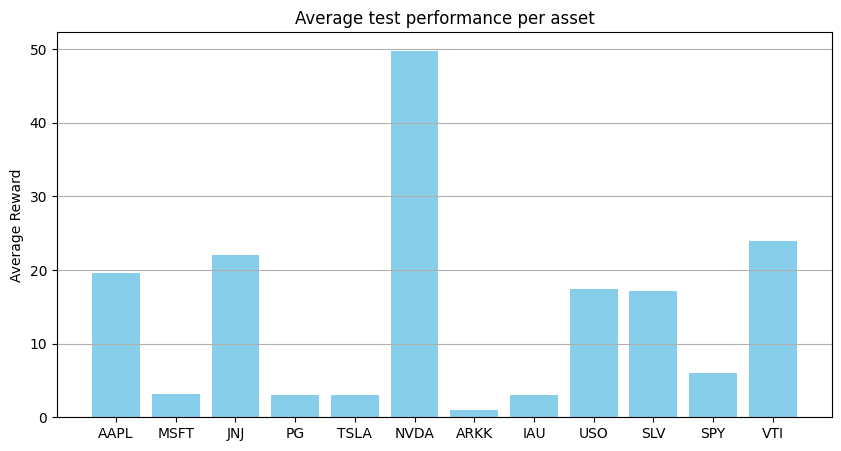

In [ ]:
# Overall reward plot per asset
asset_reward_map = {symbol: [] for symbol in tickers}
idx = 0
for symbol in tickers:
    for _ in range(5):
        asset_reward_map[symbol].append(test_rewards[idx])
        idx += 1

# Compute average reward for each asset
mean_rewards = [sum(asset_reward_map[sym])/len(asset_reward_map[sym]) for sym in tickers]

plt.figure(figsize=(10, 5))
plt.bar(tickers, mean_rewards, color='skyblue')
plt.ylabel("Average Reward")
plt.title("Average test performance per asset")
plt.grid(axis='y')
plt.show()


### **Conclusions**

This first phase of the project tested a Reinforcement Learning model applied to **Financial Prediction** for **algorithmic trading**, evaluating the agent's ability to learn from synthetic data and transfer its policy to real historical series.

---

### **General Test Analysis**

We tested the agent on **12 real-world assets**, over **5 episodes** each, using two main metrics:

* **Reward**: a measure of how good the learned policy is.
* **Accuracy**: the percentage of actions matching the “true” market direction.

However, **accuracy** is not always indicative of agent quality in an RL context, so **reward** remains the primary reference metric.

---

### **Observations on Results**

* **Strong Performance**:
  The agent achieved **high average rewards** on assets such as **NVDA (49.8)**, **VTI (24.0)**, **JNJ (22.0)**, and **AAPL (19.6)**, showing good adaptability on more “readable” assets. These results confirm the agent’s ability to extract useful patterns from historical data.

* **Intermediate Performance**:
  Assets like **USO (17.4)** and **SLV (17.2)** show positive rewards with **accuracy around 50%**, indicating a coherent and non-random policy, with room for improvement in terms of learning robustness.

* **Low but Stable Performance**:
  Some assets show lower but stable average rewards, such as **MSFT (3.2)**, **PG (3.0)**, **IAU (3.0)**, and **TSLA (3.0)**. In these cases, the agent adopts cautious or neutral behavior but **never incurs losses**.

* **Isolated Underperformance**:
  Only **ARKK** shows **significantly lower performance** (reward = 1.0, accuracy = 17%), likely due to particularly erratic asset behavior or a mismatch between real dynamics and those seen during training in synthetic data.
  Notably, ARKK did not pass the Kolmogorov-Smirnov test, which clearly confirms the importance of similarity between the synthetic training asset and the real asset used during testing.

---

### **Final Considerations**

The test shows that the agent:

* Generalizes reasonably well from synthetic to real data.
* Achieves **consistent and repeatable** performance across multiple episodes.
* **Never produced negative rewards**, even on the weakest assets.
* Is influenced by the nature of the asset: more “readable” assets (such as NVDA, VTI, AAPL) are more favorable to the model.

---

### **Next Steps**

The agent will be tested in a **more realistic simulated market environment**, which introduces:

- Macroeconomic and fundamental variables
- Higher dimensionality (multiple assets simultaneously)

This will allow us to evaluate **the agent’s robustness and scalability in** a setting closer to **real-world market operations**.


# 2. Creating a Synthetic Market for Simulating a European Call and a Dynamic Portfolio

The Finance environment was built on Monte Carlo simulations and enriched with features typical of technical analysis, providing the agent with rich and informative signals.

This second part of the project introduces an agent operating in a simulated financial market. Although still relying on Monte Carlo simulations, the model integrates numerous financial features derived from synthetic data, allowing the agent to simultaneously observe multiple signals and enhance its predictive capabilities.

Specifically, we implement the simulation of a **European call** with a **discrete dynamic replication** of a **portfolio composed of a risky asset (MSFT) and a low-risk asset (SLV)**. We apply concepts from the Black-Scholes-Merton 1973 (BSM73) model, adapted to allow the **agent to learn how to dynamically rebalance the portfolio**.

The goal is to create a simulated environment where:

* The risky asset is MSFT, simulated via Geometric Brownian Motion (GBM).
* The low-risk asset is SLV, approximated as a bond or a lower-risk asset.
* A European call option on MSFT is replicated.
* The portfolio is rebalanced discretely (e.g., daily) using the BSM delta and theoretical value.
* The agent is designed to actively intervene in the rebalancing.


Basic setup and BSM formula

In [ ]:
# Graphic settings
plt.style.use('seaborn-v0_8')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

np.set_printoptions(suppress=True)
random.seed(42)

# Basic parameters
S0 = 340     # initial price of MSFT
K = 350      # strike price of the call
T = 1.0      # maturity in years
r = 0.03     # proxy for the risk-free rate
sigma = 0.25 # estimated volatility of MSFT

BSM Formula and Delta


In [ ]:
def bsm_call_value(S, K, T, t, r, sigma):
    d1 = (math.log(S / K) + (r + 0.5 * sigma**2) * (T - t)) / (sigma * math.sqrt(T - t))
    d2 = d1 - sigma * math.sqrt(T - t)
    call = S * norm.cdf(d1) - K * math.exp(-r * (T - t)) * norm.cdf(d2)
    return call

def bsm_delta(S, K, T, t, r, sigma):
    d1 = (math.log(S / K) + (r + 0.5 * sigma**2) * (T - t)) / (sigma * math.sqrt(T - t))
    return norm.cdf(d1)

GBM Simulation of MSFT (Risky Asset)

In [ ]:
def simulate_gbm(S0, T, r, sigma, steps=252):
    dt = T / steps
    prices = [S0]
    for _ in range(steps):
        z = random.gauss(0, 1)
        S_t = prices[-1] * math.exp((r - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt) * z)
        prices.append(S_t)
    return prices

gbm_msft = simulate_gbm(S0, T, r, sigma)

SLV simulation (proxy for risk-free asset)

In [ ]:
def simulate_bond_like_asset(P0, r, T, steps=252):
    dt = T / steps
    return [P0 * math.exp(r * dt * i) for i in range(steps + 1)]

slv = simulate_bond_like_asset(P0=20, r=0.01, T=T, steps=252)  # SLV as a bond-like asset

Discrete replication of the European call option

In [ ]:
def option_replication_discrete(gbm, bond, K, T, r, sigma):
    steps = len(gbm) - 1
    dt = T / steps
    res = pd.DataFrame()

    for i in range(steps):
        t = i * dt
        St = gbm[i]
        Bt = bond[i]
        C = bsm_call_value(St, K, T, t, r, sigma)
        delta = bsm_delta(St, K, T, t, r, sigma)

        if i == 0:
            b = (C - delta * St) / Bt
        else:
            V = delta_prev * gbm[i] + b_prev * bond[i]
            b = (C - delta * gbm[i]) / bond[i]

        df = pd.DataFrame({
            'time_step': [i],
            'St': [St],
            'Bt': [Bt],
            'Call_Theo': [C],
            'Delta': [delta],
            'Stock_Pos': [delta * St],
            'Bond_Pos': [b * Bt],
            'Portfolio_Val': [delta * St + b * Bt]
        })

        res = pd.concat((res, df), ignore_index=True)
        delta_prev, b_prev = delta, b

    return res

res = option_replication_discrete(gbm_msft, slv, K, T, r, sigma)


Visual comparison between the portfolio and the call option value

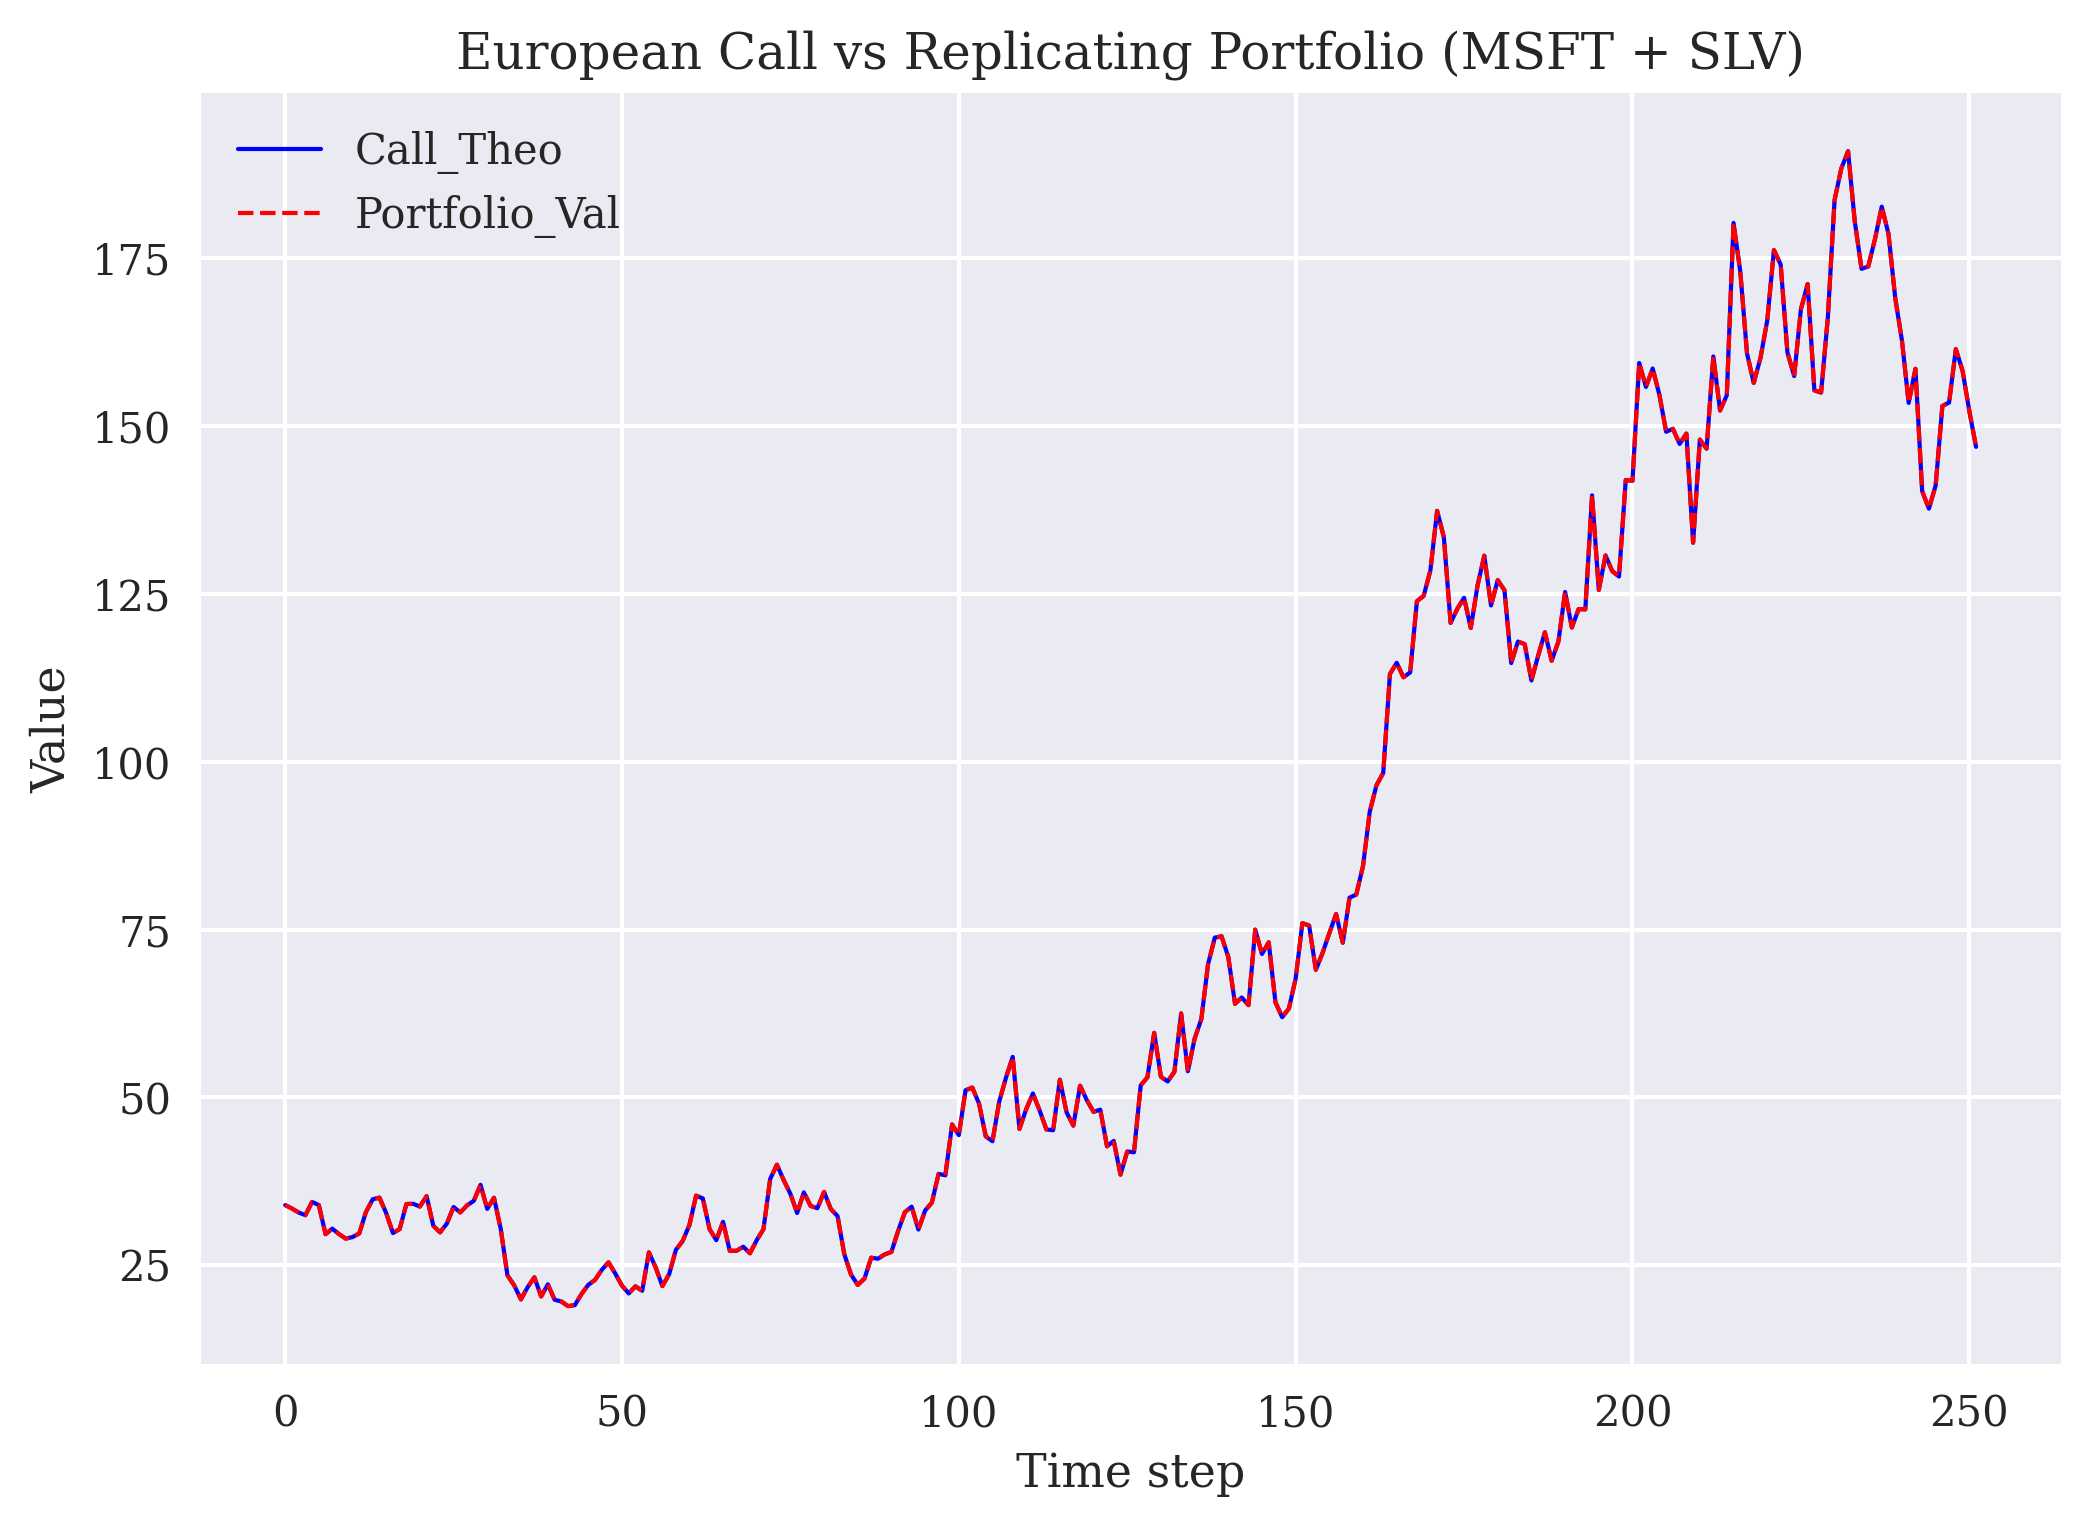

In [ ]:
res[['Call_Theo', 'Portfolio_Val']].plot(style=['b', 'r--'], lw=1)
plt.xlabel('Time step')
plt.ylabel('Value')
plt.title('European Call vs Replicating Portfolio (MSFT + SLV)')
plt.show()

Replica error analysis

MAE: 0.00000
MSE: 0.00000


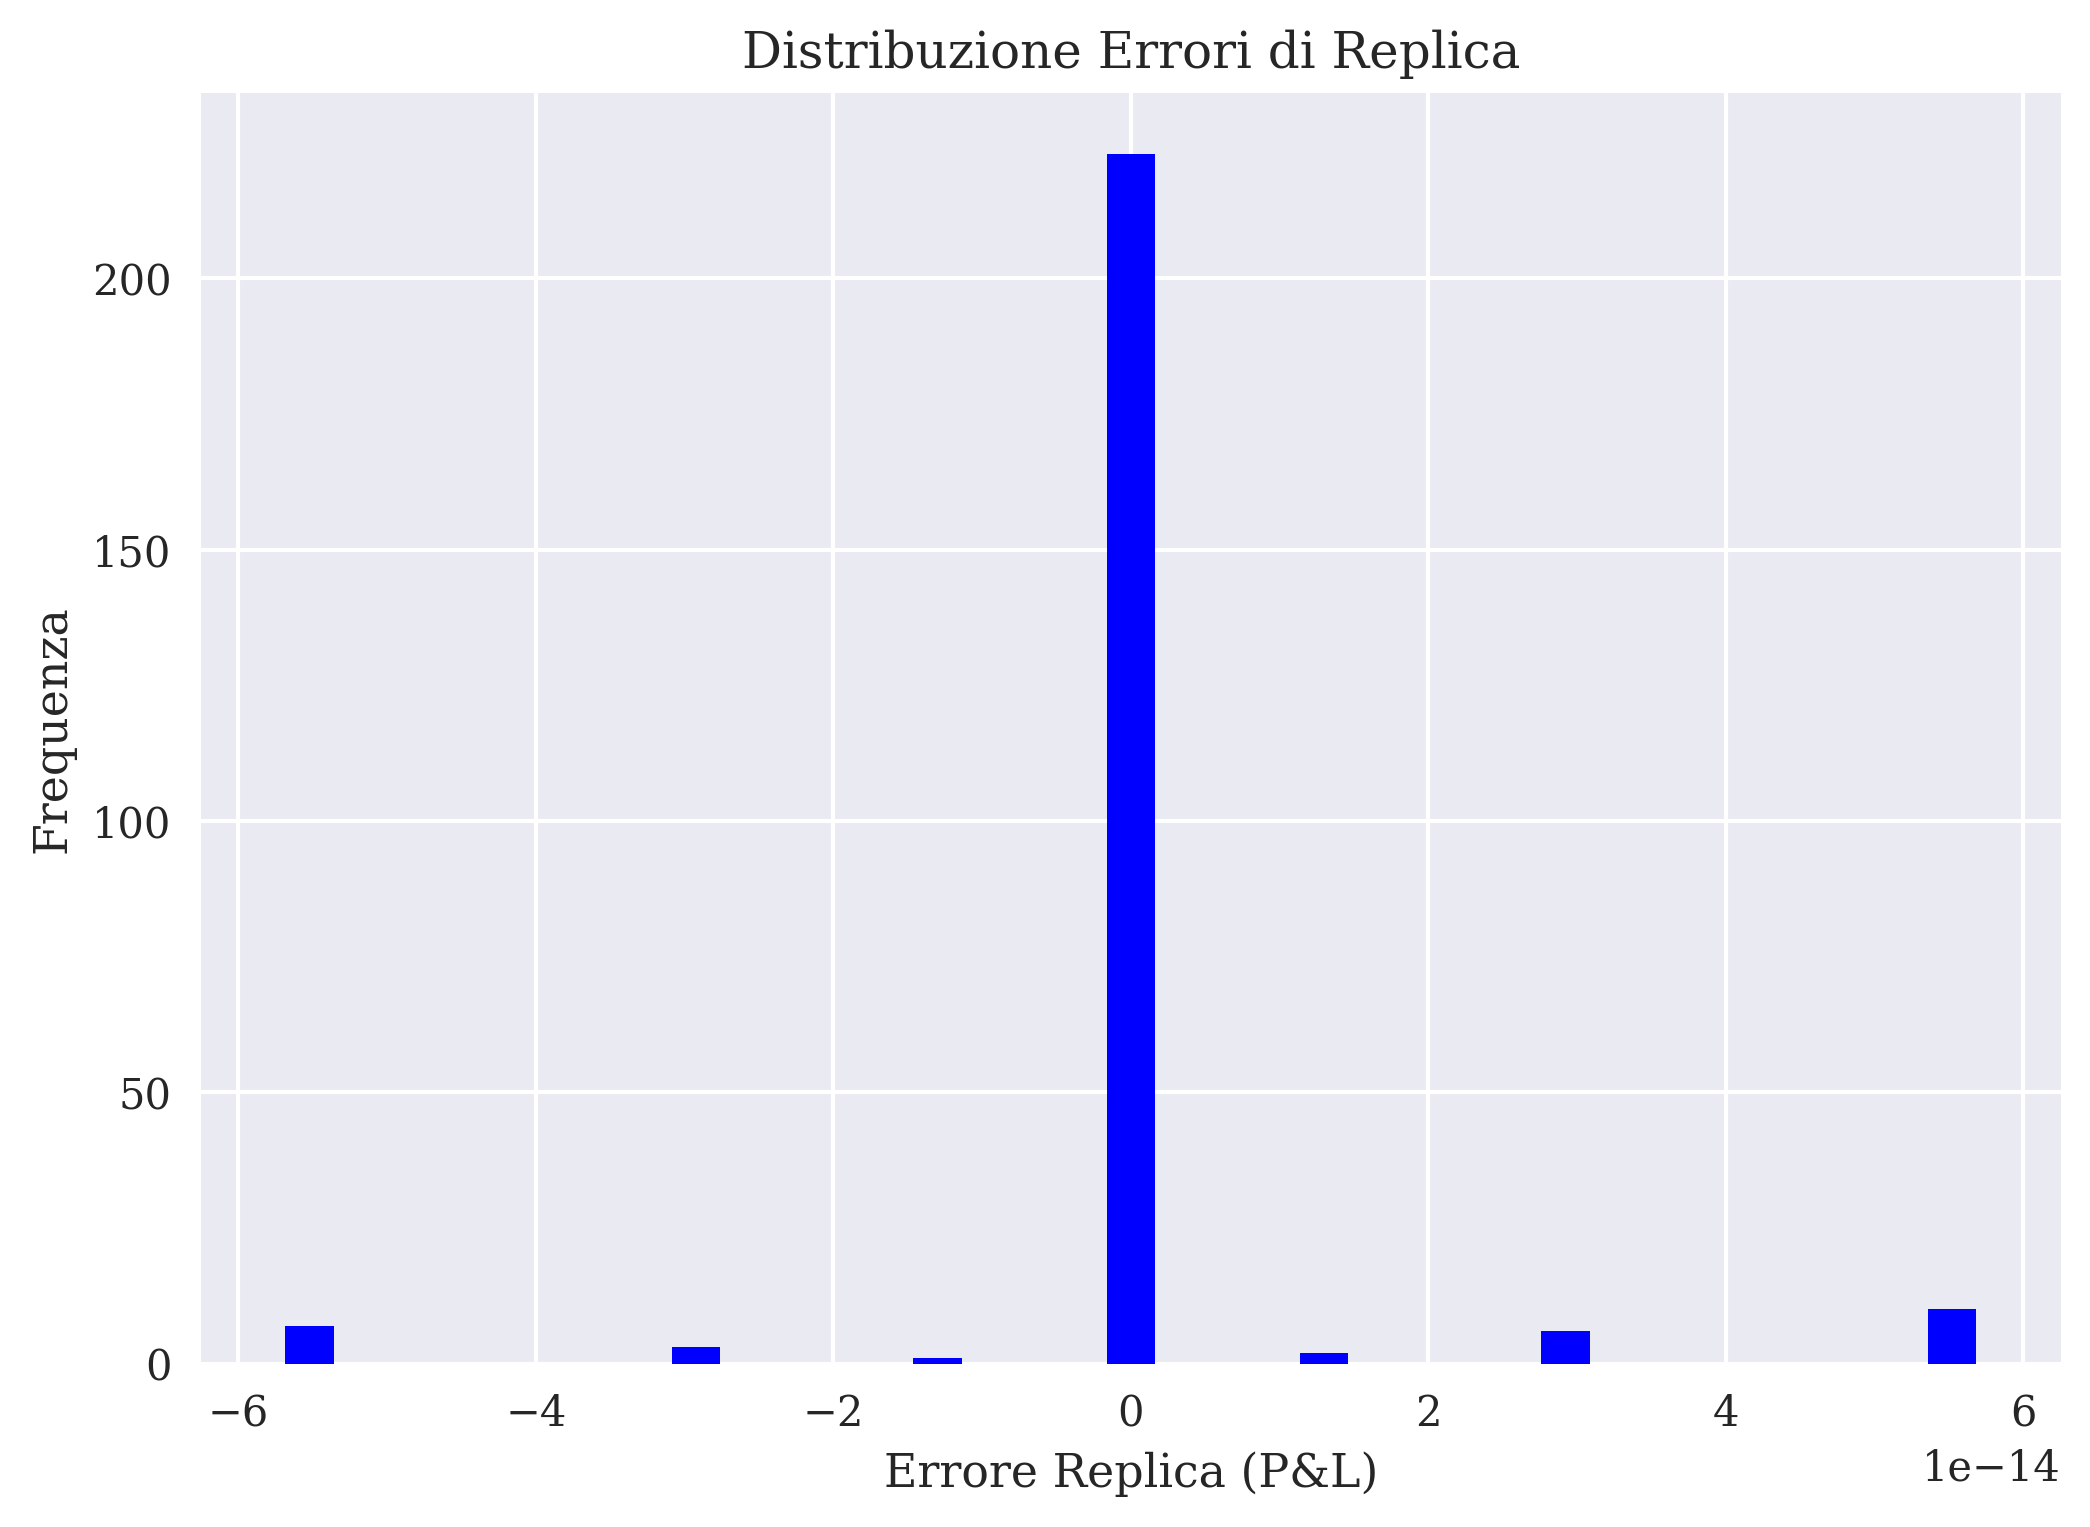

In [ ]:
# Errore medio assoluto
mae = (res['Portfolio_Val'] - res['Call_Theo']).abs().mean()

# Errore quadratico medio
mse = ((res['Portfolio_Val'] - res['Call_Theo']) ** 2).mean()

print(f"MAE: {mae:.5f}")
print(f"MSE: {mse:.5f}")

# Istogramma degli errori
(res['Portfolio_Val'] - res['Call_Theo']).hist(bins=35, color='b')
plt.xlabel('Errore Replica (P&L)')
plt.ylabel('Frequenza')
plt.title('Distribuzione Errori di Replica')
plt.show()

**Conclusions**

* The discrete delta replication model appears to work **virtually perfectly** in the simulated context.
* Practically, the portfolio constructed with the MSFT stock and SLV (bond proxy) has **faithfully replicated** the dynamic payoff of the call according to the BSM model.

In fact, in the **Replication Error Distribution**, the visualization **compares two time series** and analyzes the **difference** between these two series:

* `**Portfolio_Val**`: value of the replicating portfolio (MSFT + SLV)
* `**Call_Theo**`: theoretical value of the European call according to Black-Scholes

We observe:

**1. MAE and MSE (virtually zero)**

```
MAE: 0.00000
MSE: 0.00000
```

This means that **the mean absolute error (MAE) and mean squared error (MSE) are practically null**, indicating a **perfect replication** of the theoretical call via the delta-hedged portfolio.

**2. Histogram chart**, where:

* The X axis represents the error value (Profit & Loss of the replication).
* The Y axis shows **the frequency** of each error occurrence.

A **very tall bar centered at zero** indicates that the vast majority of errors are **exactly or nearly zero**.
Other bars, very low, confirm the presence of very few errors, attributable to **numerical approximations** or minimal floating-point calculation fluctuations.


# 3. Simulation of a Hedging Environment

Let’s take a step forward by testing the agent in a **dynamic hedging** context, made more realistic through a **complex interactive simulated environment**. Unlike the classic Black-Scholes model, where strategies are static and based on closed formulas, here the agent learns **sequentially** how to manage a portfolio composed of a risky asset (such as a stock index) and a risk-free bond.

To guide its decisions, the environment now provides **8 financial input variables**, offering a broader and more comprehensive market view:

* Index price
* Bond price
* Log-return
* Moving average
* Volatility
* Time to maturity
* Average price
* Momentum

The `HedgingMock` environment simulates each episode as a different market trajectory. At each step, the agent chooses **what proportion of the risky asset to hold** (`phi`), while the rest of the capital is allocated to the bond. The portfolio is updated, valued, and subject to a random component reflecting market uncertainty. All data are recorded in a dataframe tracking prices, decisions, portfolio value, and profits/losses.

Compared to a static replication, this approach allows training the agent on **multiple scenarios**, making it more adaptive and capable of operating in uncertain markets. Decisions no longer depend only on price but arise from a **combined processing of complex signals**. The agent thus develops an **active and autonomous strategy**, continuously evolving with the goal of optimizing hedging over time.

**To evaluate the agent’s effectiveness, we will compare the performance of a portfolio built with random actions (no strategy or learning) to that of a deep reinforcement learning agent trained to replicate the derivative.**

In [ ]:
class HedgingMock:
    def __init__(self, steps=100):
        self.steps = steps
        self.current_step = 0
        self._generate_data()
        self.action_space = self  # for .sample()
        self.portfolios = pd.DataFrame(columns=['s', 'b', 'phi', 'C', 'p&l[$]', 'p&l[%]', 'St', 'Bt'])
        self.stock = 0.5

    def _generate_data(self):
        index = 100 + np.cumsum(np.random.normal(0, 1, self.steps))
        bond = 100 * np.exp(0.01 * np.linspace(0, 1, self.steps))
        log_ret = np.log(index / np.roll(index, 1))
        ma = pd.Series(index).rolling(window=5).mean().fillna(method='bfill')
        vol = pd.Series(log_ret).rolling(window=5).std().fillna(method='bfill')
        ttm = np.linspace(1, 0, self.steps)  # time to maturity
        avg_price = pd.Series(index).expanding().mean()
        momentum = pd.Series(index).diff().fillna(0)

        self.data = pd.DataFrame({
            'Index': index,
            'Bond': bond,
            'LogRet': log_ret,
            'MA': ma,
            'Vol': vol,
            'TTM': ttm,
            'AvgP': avg_price,
            'Mom': momentum
        }).fillna(0)

    def sample(self):
        return np.random.uniform(0, 1)

    def reset(self):
        self.current_step = 0
        self._generate_data()
        self.portfolios = pd.DataFrame(columns=self.portfolios.columns)
        obs = self.data.iloc[0]
        return obs, {}

    def step(self, action):
        if self.current_step >= self.steps:
            raise StopIteration("End of episode.")

        row_data = self.data.iloc[self.current_step]
        St = row_data['Index']
        Bt = row_data['Bond']
        phi = action
        b = (100 - phi * St) / Bt
        C = phi * St + b * Bt
        pnl_abs = np.random.normal(0, 0.1)
        pnl_pct = pnl_abs / C * 100

        row = {
            's': round(phi, 4),
            'b': round(b, 4),
            'phi': round(C, 4),
            'C': round(C - pnl_abs, 4),
            'p&l[$]': round(pnl_abs, 4),
            'p&l[%]': round(pnl_pct, 2),
            'St': round(St, 2),
            'Bt': round(Bt, 2)
        }

        self.portfolios.loc[self.current_step] = row
        self.current_step += 1

        done = self.current_step >= self.steps
        return row_data, pnl_abs, done, False, {}


Simulated Prices Visualization

In [ ]:
hedging = HedgingMock(steps=100)
obs, _ = hedging.reset()

for _ in range(hedging.steps - 1):
    obs, reward, done, truncated, info = hedging.step(hedging.action_space.sample())
    if done:
        break

print(hedging.portfolios.head())

        s       b    phi         C  p&l[$]  p&l[%]      St      Bt
0  0.7119  0.2797  100.0  100.0620 -0.0620   -0.06  101.18  100.00
1  0.6512  0.3314  100.0  100.0438 -0.0438   -0.04  102.66  100.01
2  0.3792  0.6125  100.0   99.9871  0.0129    0.01  102.16  100.02
3  0.4571  0.5329  100.0   99.9507  0.0493    0.05  102.16  100.03
4  0.1161  0.8830  100.0   99.9335  0.0665    0.07  100.48  100.04


Normalized Simulated Prices Visualization

In [ ]:
print(hedging.data.columns)

Index(['Index', 'Bond', 'LogRet', 'MA', 'Vol', 'TTM', 'AvgP', 'Mom'], dtype='object')


<Figure size 1800x1200 with 0 Axes>

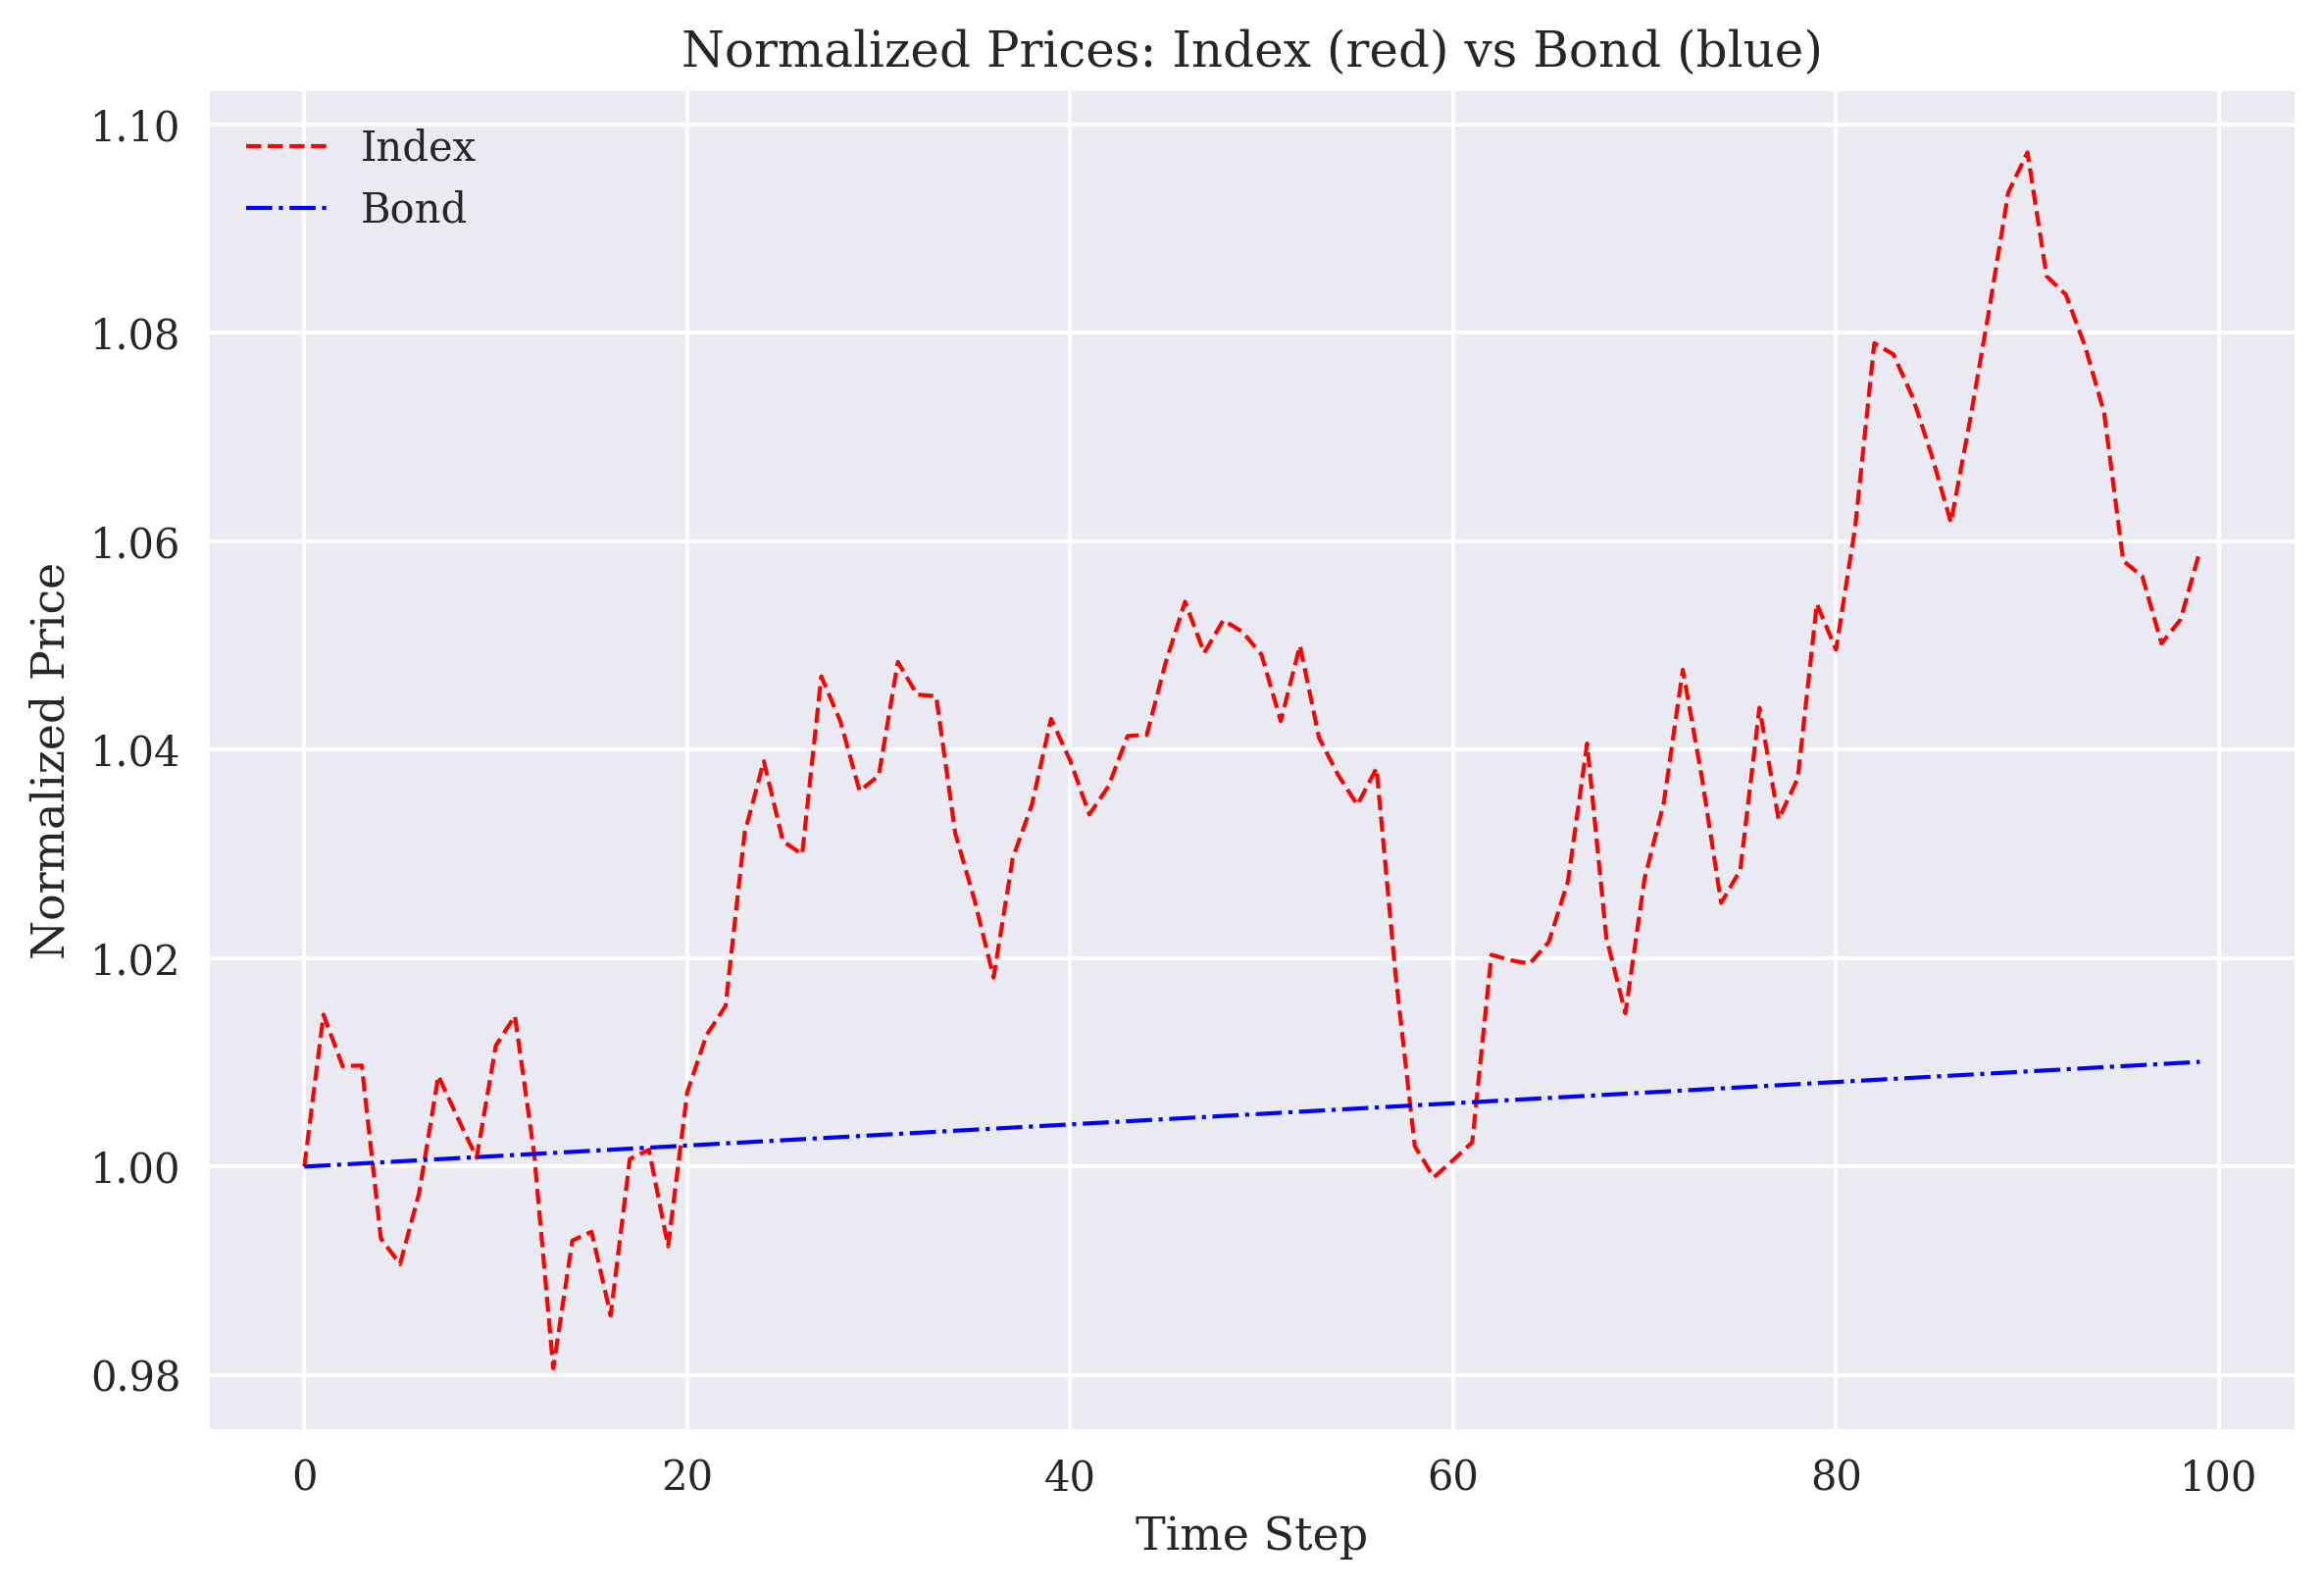

In [ ]:
plt.figure(figsize=(6, 4))
(hedging.data[['Index', 'Bond']] / hedging.data[['Index', 'Bond']].iloc[0]).plot(lw=1.0, style=['r--', 'b-.'])
plt.xlabel('Time Step')
plt.ylabel('Normalized Price')
plt.title('Normalized Prices: Index (red) vs Bond (blue)')
plt.grid(True)
plt.tight_layout()
plt.show()

Plot: Normalized trend of Index (red) and Bond (blue).

The plot shows the components of the simulation: the index exhibits wide variability, while the bond follows a moderate linear growth. This creates a realistic environment to test dynamic hedging strategies.

**Simulation 1 - Portfolio constructed with random actions (without strategy or learning)**

Random Agent Execution

In [ ]:
hedging.reset()
for _ in range(hedging.steps - 1):
    hedging.step(hedging.action_space.sample())

First Rows of the Random Portfolio

In [ ]:
print(hedging.portfolios.head().round(4))

        s       b    phi         C  p&l[$]  p&l[%]      St      Bt
0  0.7185  0.2823  100.0   99.9948  0.0052    0.01   99.89  100.00
1  0.8540  0.1393  100.0  100.1518 -0.1518   -0.15  100.78  100.01
2  0.5911  0.4070  100.0  100.1304 -0.1304   -0.13  100.32  100.02
3  0.3513  0.6410  100.0   99.9693  0.0307    0.03  102.13  100.03
4  0.0177  0.9814  100.0  100.1063 -0.1063   -0.11  102.69  100.04


* **p\&l\[\$]**: Profit & Loss in absolute value. Indicates how much the portfolio gained or lost in monetary terms (e.g., dollars) at that step.

* **p\&l\[%]**: Profit & Loss in percentage terms.

Replication vs Option Comparison

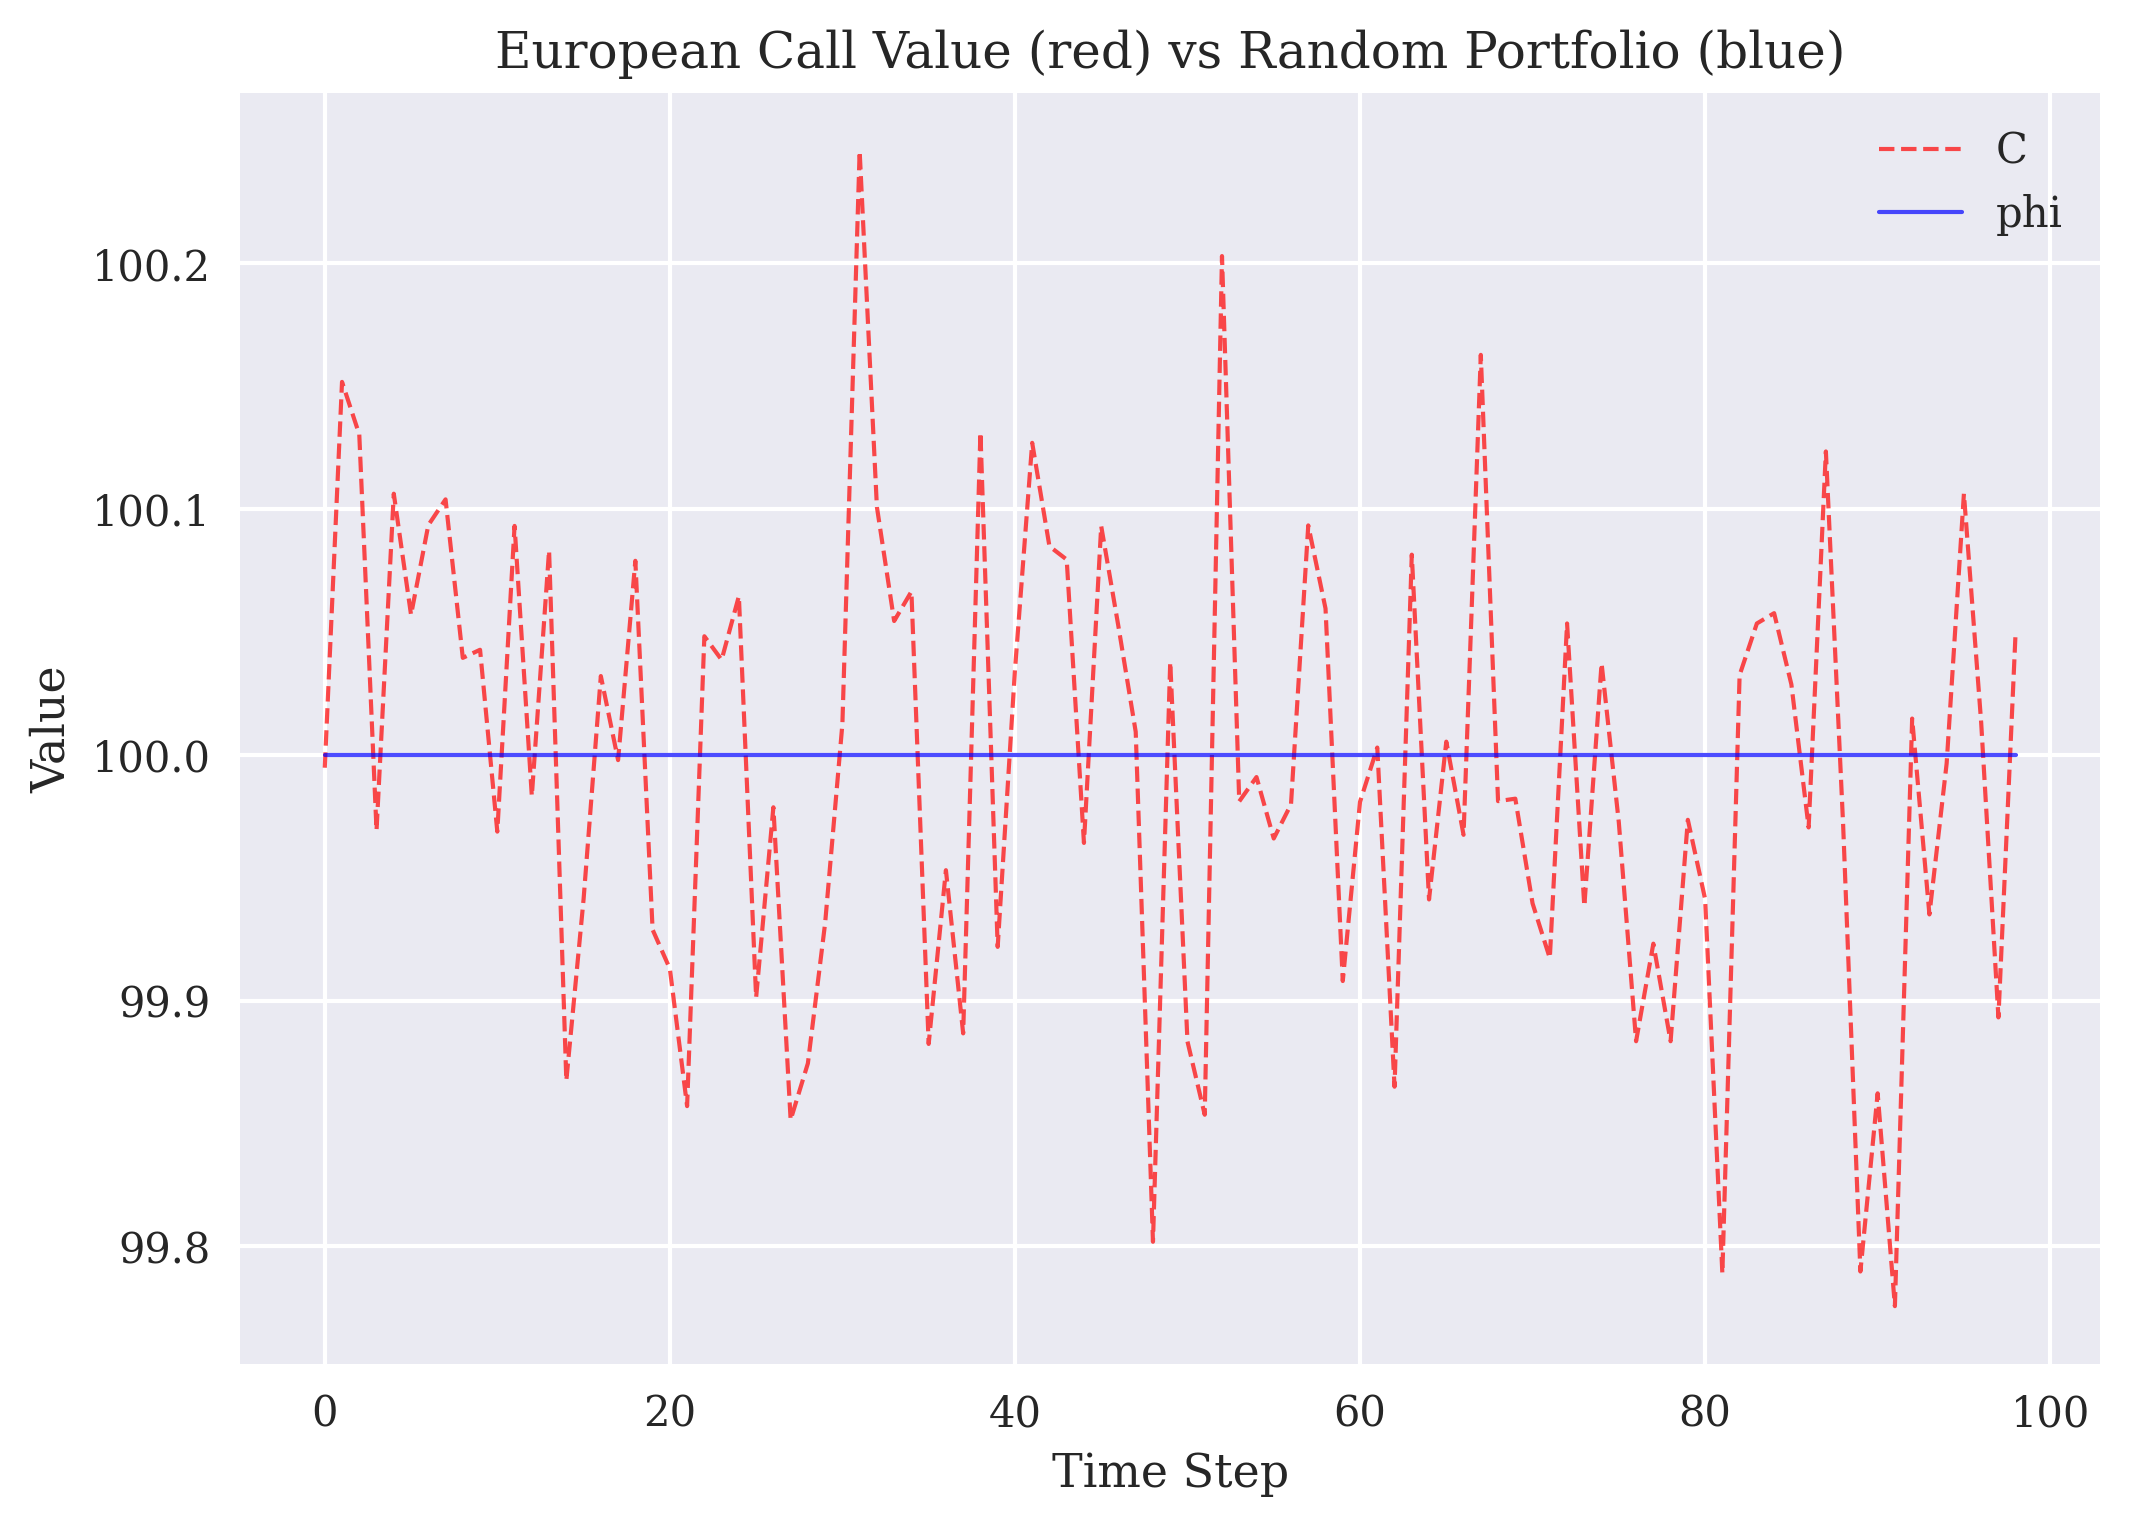

In [ ]:
hedging.portfolios[['C', 'phi']].plot(style=['r--', 'b-'], lw=1, alpha=0.7)
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('European Call Value (red) vs Random Portfolio (blue)')
plt.grid(True)
plt.show()

Chart: Comparison between theoretical call value (C, red dashed) and random portfolio (phi, blue line).

The blue line remains constant since the random agent holds a fixed share of the stock. The portfolio value fluctuates around the theoretical value without accurately replicating it, showing clear misalignment between the expected call value and the portfolio.

Histogram of Absolute Errors (P&L)

Sum of absolute errors: 7.47


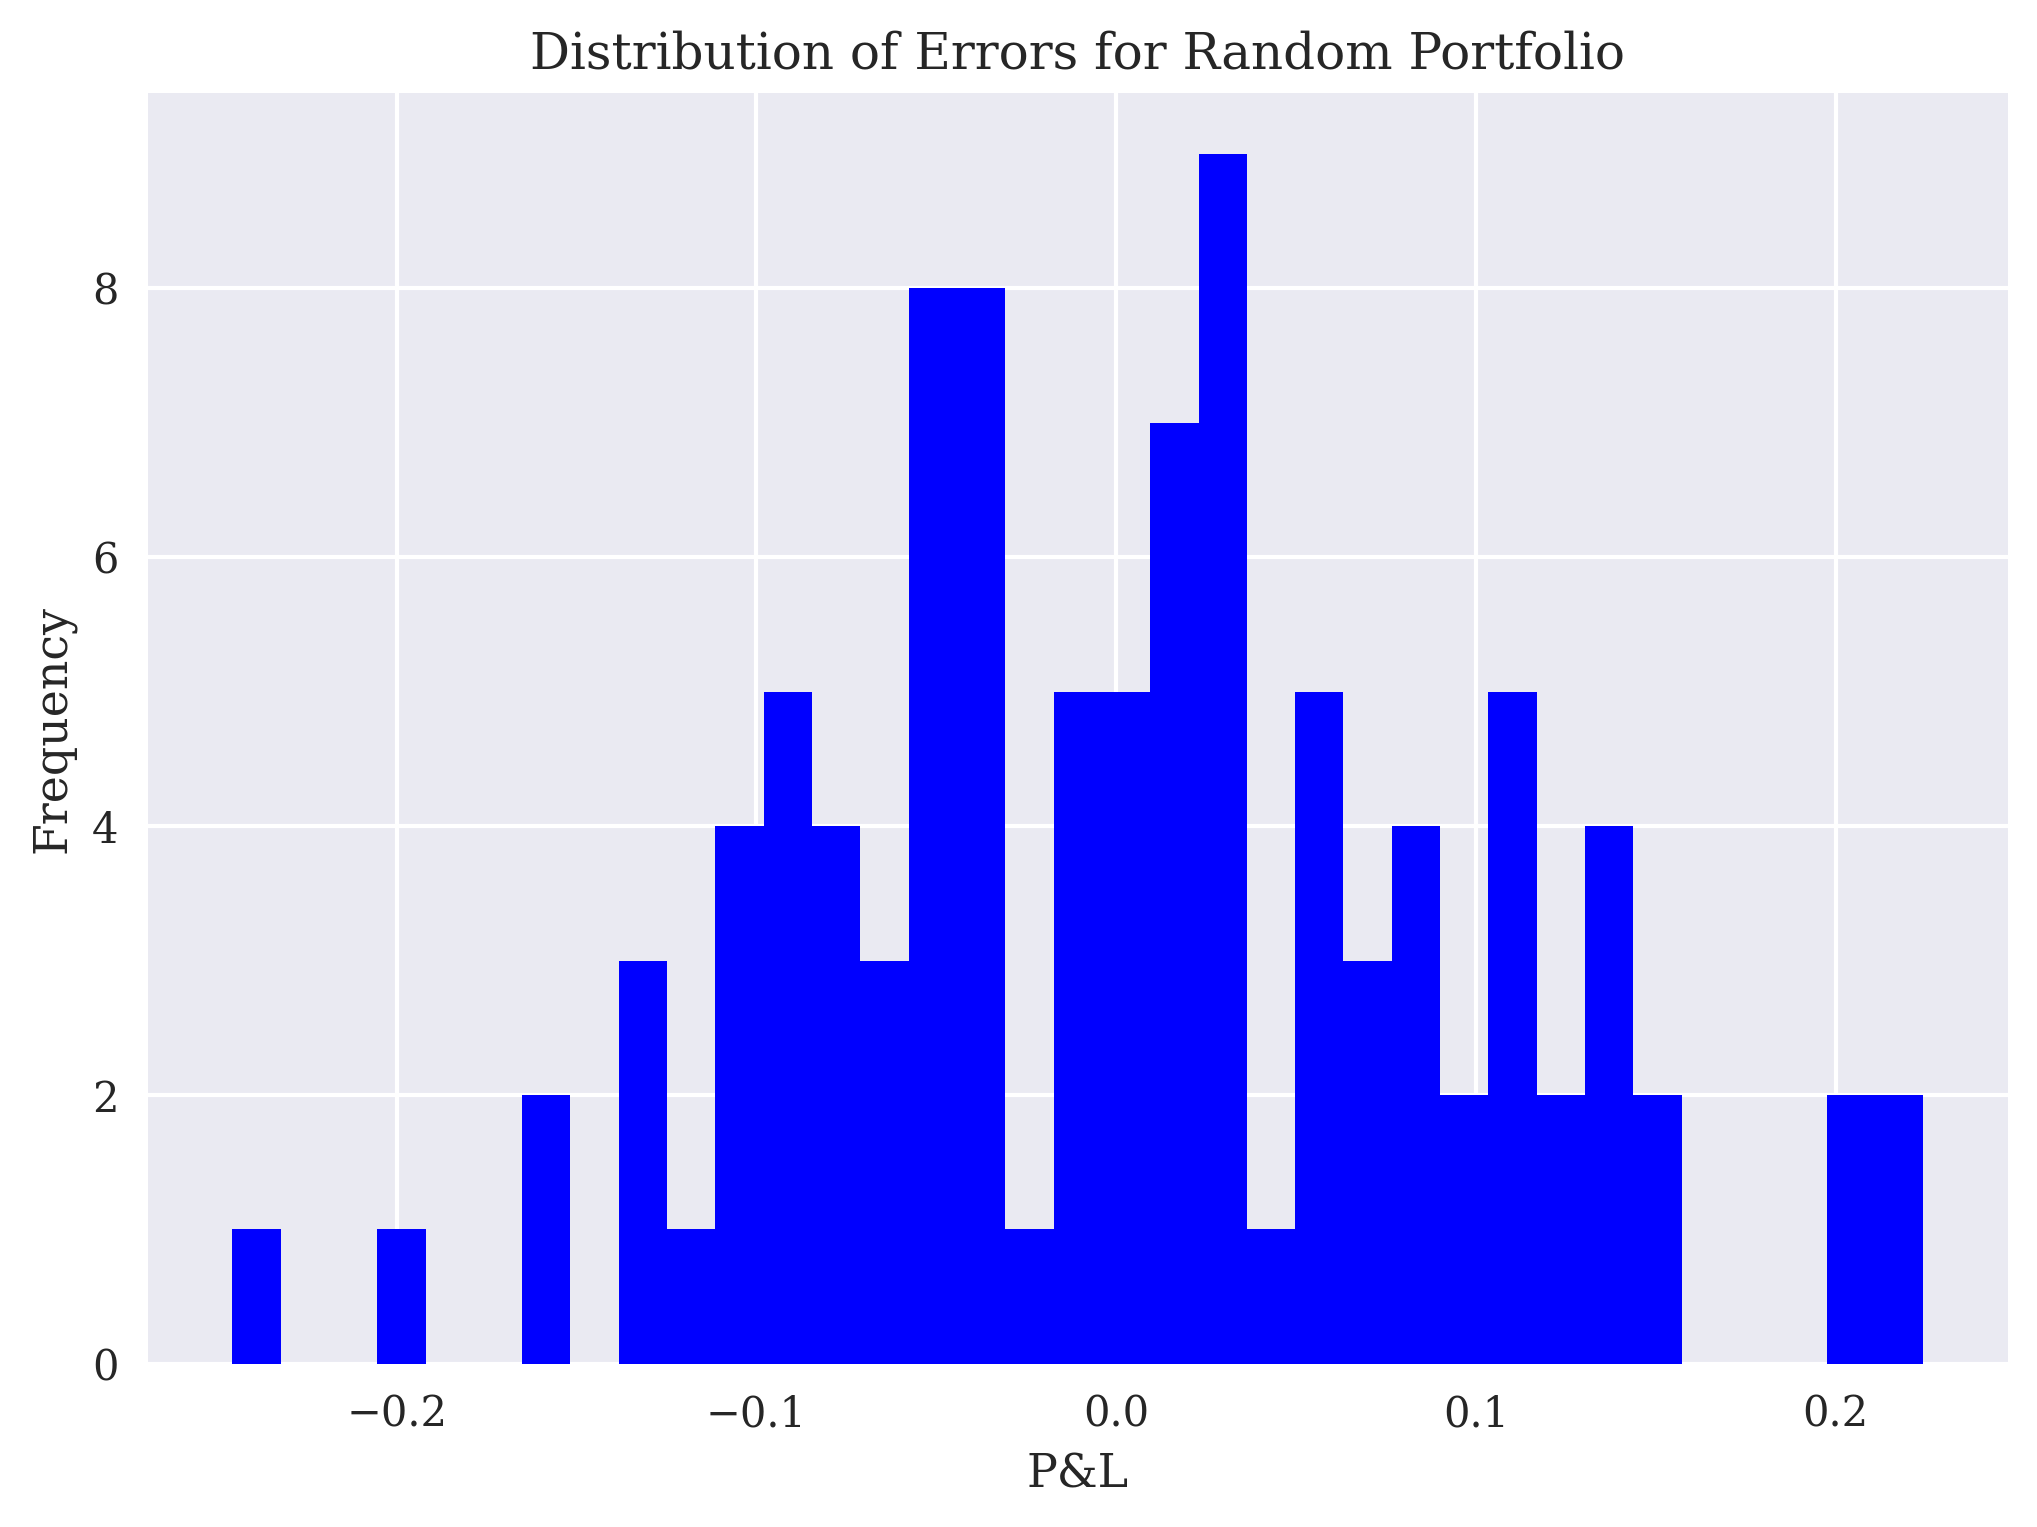

In [ ]:
total_abs_error = hedging.portfolios['p&l[$]'].abs().sum()
print(f"Sum of absolute errors: {total_abs_error:.2f}")

hedging.portfolios['p&l[$]'].hist(bins=35, color='b')
plt.xlabel('P&L')
plt.ylabel('Frequency')
plt.title('Distribution of Errors for Random Portfolio')
plt.grid(True)
plt.show()

Chart: Histogram of replication errors for the random portfolio.

The distribution is wide and dispersed: errors are not centered around zero, and the frequency spreads over a large range. Unlike what we observed in Part 2, where:

MAE ≈ 0

MSE ≈ 0

with a pronounced bar exactly at zero, the purely random portfolio generates significant and widespread errors. This clearly highlights that, in the absence of an active strategy (neither agent nor rule), the replication of the call fails.

Thus, we confirm the need for an intelligent agent, capable of utilizing the 8 informative features and making step-by-step decisions to improve the quality of the dynamic replication.

**Simulation 2 - Performance of a trained deep reinforcement learning agent**

Creation of the HedgingAgent Class (from DQLAgent)

In [ ]:
class DQLAgent:
    def __init__(self, symbol, feature, n_features, env, hu=64, lr=0.001):
        self.symbol = symbol
        self.feature = feature
        self.n_features = n_features
        self.env = env
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = 0.995
        self.batch_size = 32
        self.memory = []
        self._create_model(hu, lr)

    def _create_model(self, hu, lr):
        self.model = Sequential()
        self.model.add(Dense(hu, input_dim=self.n_features, activation='relu'))
        self.model.add(Dense(hu, activation='relu'))
        self.model.add(Dense(1, activation='linear'))
        self.model.compile(loss='mse', optimizer=Adam(learning_rate=lr))

    def _reshape(self, state):
        # Converts pandas Series or array-like to 2D numpy array
        return np.reshape(state.values if hasattr(state, 'values') else state, [1, self.n_features])

    def remember(self, state, action, next_state, reward, done):
        self.memory.append((state, action, next_state, reward, done))
        if len(self.memory) > 2000:
            self.memory.pop(0)

    def replay(self):
        if len(self.memory) < self.batch_size:
            return
        batch = random.sample(self.memory, self.batch_size)
        for state, action, next_state, reward, done in batch:
            target = reward
            if not done:
                predicted = self.model.predict(next_state, verbose=0)[0][0]
                target += self.gamma * predicted
            self.model.fit(state, np.array([target]), epochs=1, verbose=0)
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay


opt\_action method: Continuous Action Optimization

In [ ]:
class HedgingAgent(DQLAgent):
    def opt_action(self, state):
        bnds = [(0, 1)]

        def f(s, x):
            St = s[0, 0]
            Bt = s[0, 1]
            phi = x[0]
            b = (100 - phi * St) / Bt
            C = phi * St + b * Bt
            return C

        try:
            result = minimize(lambda x: -f(state, x), x0=[0.5], bounds=bnds, method='Powell')
            action = result.x[0]
        except Exception as e:
            print("Error in opt_action:", e)
            action = self.env.sample()
        return action

Extended replay method: Learning from past experiences

In [ ]:
class HedgingAgent(HedgingAgent):
    def replay(self):
        if len(self.memory) < self.batch_size:
            return

        batch = random.sample(self.memory, self.batch_size)
        for state, action, next_state, reward, done in batch:
            target = reward
            if not done:
                opt_act = self.opt_action(next_state)
                target += self.gamma * self.model.predict(next_state, verbose=0)[0, 0]
            self.model.fit(state, np.array([target]), epochs=1, verbose=0)

        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay


Test method: Evaluation of the learned strategy

In [ ]:
class HedgingAgent(HedgingAgent):
    def test(self, episodes, verbose=True):
        for e in range(1, episodes + 1):
            state, _ = self.env.reset()
            state = self._reshape(state)
            treward = 0
            for _ in range(1, len(self.env.data) + 1):
                action = self.opt_action(state)
                state, reward, done, trunc, _ = self.env.step(action)
                state = self._reshape(state)
                treward += reward
                if done:
                    if verbose:
                        print(f'[Episode {e}] Total penalty = {treward:.2f}')
                    break

Learn method: Continuous learning

In [ ]:
class HedgingAgent(HedgingAgent):
    def learn(self, episodes=10):
        for e in range(1, episodes + 1):
            state, _ = self.env.reset()
            state = self._reshape(state)
            treward = 0
            for _ in range(self.env.steps):
                if np.random.rand() <= self.epsilon:
                    action = self.env.sample()
                else:
                    action = self.opt_action(state)

                next_state, reward, done, truncated, _ = self.env.step(action)
                next_state = self._reshape(next_state)
                self.remember(state, action, next_state, reward, done)
                state = next_state
                treward += reward
                if done:
                    break
            self.replay()
            print(f"[TRAIN Episode {e}] Total reward: {treward:.2f}")


Agent Training with Learning

In [ ]:
random.seed(100)
np.random.seed(100)
tf.random.set_seed(100)

hedgingagent = HedgingAgent('SYM', feature=None, n_features=8, env=hedging, hu=128, lr=0.0001)
episodes = 10
%time hedgingagent.learn(episodes)


[TRAIN Episode 1] Total reward: 1.50
[TRAIN Episode 2] Total reward: 0.72
[TRAIN Episode 3] Total reward: 0.11
[TRAIN Episode 4] Total reward: -0.36
[TRAIN Episode 5] Total reward: -1.37
[TRAIN Episode 6] Total reward: -0.47
[TRAIN Episode 7] Total reward: 0.51
[TRAIN Episode 8] Total reward: -0.23
[TRAIN Episode 9] Total reward: 0.93
[TRAIN Episode 10] Total reward: 0.37
CPU times: user 1min 12s, sys: 1.31 s, total: 1min 14s
Wall time: 1min 19s


The agent training shows a progression with initially positive rewards, then fluctuating, indicating that the agent is exploring the action space and gradually learning an effective policy. Although not all episodes show consistent positive results, the agent appears to be learning profitable strategies since most rewards are positive.

In contrast to the random portfolio, which consistently fails, we observe a learning structure aiming to adaptively minimize error.

**Conclusions**

The project demonstrates how Deep Reinforcement Learning can be effectively applied to complex financial problems, from predictive analysis on real and synthetic data to dynamic derivative replication and portfolio optimization in multi-feature environments.

The use of synthetic data enabled more robust training of agents, overcoming the limitations of scarce and noisy real-world data. The numerical replication of a European call confirmed the effectiveness of discrete rebalancing strategies, with minimal errors.

Finally, the multi-dimensional stochastic hedging environment highlighted the RL agent’s ability to manage complex and variable signals, providing a promising foundation for developing agent-based systems for dynamic risk management and portfolio optimization in realistic and noisy financial contexts.